# **Project Name**    - Real Estate Investment Advisor: Predicting Property Profitability & Future Value

##### **Project Type**    - EDA / Classification / Regression
##### **Contribution**    - Individual
##### **Member -** Adarsh Shrikant Tiwari

# **Project Summary -**

Buying property is the single largest investment most Indian households make, yet the decision is usually driven by broker opinion, word of mouth and gut feeling rather than data. This project builds a **Real Estate Investment Advisor**: a machine-learning application that tells a potential investor (1) whether a listed property is a **Good Investment** and (2) what the property is likely to be worth **five years from now**.

The work uses the `india_housing_prices.csv` dataset of **250,000 residential listings** spread across **20 states, 42 cities and 500 localities**. Each record describes the property (type, BHK, size, price, year built, floor, furnishing), its neighbourhood (nearby schools, hospitals, public-transport access), its features (parking, security, amenities, facing) and its listing context (owner type, availability status).

**Data understanding & wrangling.** The data has no missing values and no duplicates, but it is not perfectly clean. In 46.5 % of rows the floor number is higher than the total floors of the building, which is physically impossible; these values were treated as swapped and corrected. The supplied `Price_per_SqFt` column is stored in lakhs and rounded to two decimals, which destroys most of its precision, so it was rebuilt in rupees from price and size. Price per sq ft is strongly right-skewed (small flats with high prices), and 19,723 extreme values were capped using the IQR rule rather than deleted, so no listing is lost. Age of property was recomputed from the year built.

**Feature engineering.** New features were created to capture investment logic: amenity flags and an amenity count, an **Infrastructure Score** (schools, hospitals and transport combined on a 0-10 scale), a **School Density Score**, a **City Tier** (Tier 1/2/3), and two market-relative features that compare each property's price and price per sq ft with its city median.

**Target creation.** Because the data has no historical sale prices, both targets were built from transparent domain rules, as suggested in the project brief. The **future price** follows `Future = Current × (1 + r)^5`, where *r* starts at 8 % a year and is adjusted for city tier, transport, infrastructure, construction stage, property type, age and amenities, plus a small random market-noise term. **Good Investment** is a multi-factor score (0-10) that rewards properties priced below their city median, family-size homes (3+ BHK), ready-to-move status, good transport and infrastructure, amenities, security, parking and above-benchmark appreciation; a score of 5.5 or more is labelled *good* (54.8 % of listings).

**EDA.** Twenty-five charts following the UBM rule answer the twenty questions in the brief. The central finding is that raw prices in this dataset are almost uniformly spread: average prices differ by less than 3 % between cities and states, and price is essentially uncorrelated with size, BHK, schools, hospitals, furnishing or facing. In practice this means **an investor cannot rely on the listed price alone to tell value**, and the real differentiators are relative value (price vs the city median) and the quality factors in the investment score: transport access (74 % of high-access listings are good investments vs 34 % of low-access ones), city tier, BHK, amenities and readiness.

**Modelling.** Three classifiers (Logistic Regression, Random Forest, XGBoost) and three regressors (Linear Regression, Random Forest, XGBoost) were trained on an 80/20 stratified split, with every run logged in **MLflow**. XGBoost won both tasks: **accuracy 99.6 %, F1 0.996, ROC-AUC 0.9999** for classification and **RMSE ≈ 10.4 lakh, R² 0.998** for the 5-year price. The champions were registered in the MLflow Model Registry.

**Deployment.** A **Streamlit** app lets a user enter any property and instantly see the investment verdict with a confidence score, the 5-year price forecast with a projection chart, a factor-by-factor explanation and feature importance, plus a property explorer with filters and market insight dashboards (location heatmaps, trend charts).

# **GitHub Link -**

Provide your GitHub Link here.

# **Problem Statement**

**Develop a machine learning application to assist potential investors in making real estate decisions.** The system should:

1. **Classify** whether a property is a *Good Investment* (classification).
2. **Predict** the estimated property price after 5 years (regression).

The provided dataset must be pre-processed and analysed, relevant features engineered, and a user-interactive **Streamlit** application deployed that gives investment recommendations and price forecasts, with **MLflow** used for experiment tracking.

#### **Define Your Business Objective?**

Help investors, home buyers and real-estate platforms make **data-backed property decisions** by:

* flagging listings that offer good long-term value relative to their market,
* estimating the expected 5-year resale value so buyers can compare returns,
* automating investment screening for large listing inventories, and
* increasing customer trust in the platform through transparent, explainable predictions.

# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.

     The additional credits will have advantages over other students during Star Student selection.

             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.


```
# Chart visualization code
```


*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 20 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]

# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [1]:
# Import Libraries
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import logging
warnings.filterwarnings("ignore")              # keep the notebook output clean
logging.getLogger("matplotlib").setLevel(logging.WARNING)
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", palette="crest")
plt.rcParams["figure.dpi"] = 100
PRIMARY, GOOD, BAD = "#1f6f8b", "#2a9d8f", "#e76f51"

# Locate the project root whether the notebook is run from /notebooks or the root
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.append(str(ROOT / "src"))

# Project modules (same functions are used by the training script and the app)
import config as cfg
from data_preprocessing import (clean_data, build_city_reference_stats,
                                engineer_features, create_targets)
print("Project root:", ROOT)

Project root: /home/claude/rea/Real_Estate_Investment_Advisor


### Dataset Loading

In [2]:
# Load Dataset (with a clear error if the file is missing)
try:
    raw_df = pd.read_csv(cfg.RAW_DATA_PATH)
except FileNotFoundError:
    raise FileNotFoundError(f"Dataset not found at {cfg.RAW_DATA_PATH}. "
                            "Put india_housing_prices.csv in data/raw/")

### Dataset First View

In [3]:
# Dataset First Look
raw_df.head()

,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,Furnished_Status,Floor_No,Total_Floors,Age_of_Property,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status
0,1,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.76,0.10,1990,Furnished,22,1,35,10,3,High,No,No,"Playground, Gym, Garden, Pool, Clubhouse",West,Owner,Ready_to_Move
1,2,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.52,0.08,2008,Unfurnished,21,20,17,8,1,Low,No,Yes,"Playground, Clubhouse, Pool, Gym, Garden",North,Builder,Under_Construction
2,3,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.79,0.05,1997,Semi-furnished,19,27,28,9,8,Low,Yes,No,"Clubhouse, Pool, Playground, Gym",South,Broker,Ready_to_Move
3,4,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,300.29,0.11,1991,Furnished,21,26,34,5,7,High,Yes,Yes,"Playground, Clubhouse, Gym, Pool, Garden",North,Builder,Ready_to_Move
4,5,Rajasthan,Jaipur,Locality_466,Villa,4,4823,182.90,0.04,2002,Semi-furnished,3,2,23,4,9,Low,No,Yes,"Playground, Garden, Gym, Pool, Clubhouse",East,Builder,Ready_to_Move


### Dataset Rows & Columns count

In [4]:
# Dataset Rows & Columns count
print(f"Rows: {raw_df.shape[0]:,}   Columns: {raw_df.shape[1]}")

Rows: 250,000   Columns: 23


### Dataset Information

In [5]:
# Dataset Info
raw_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 23 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   ID                              250000 non-null  int64  
 1   State                           250000 non-null  str    
 2   City                            250000 non-null  str    
 3   Locality                        250000 non-null  str    
 4   Property_Type                   250000 non-null  str    
 5   BHK                             250000 non-null  int64  
 6   Size_in_SqFt                    250000 non-null  int64  
 7   Price_in_Lakhs                  250000 non-null  float64
 8   Price_per_SqFt                  250000 non-null  float64
 9   Year_Built                      250000 non-null  int64  
 10  Furnished_Status                250000 non-null  str    
 11  Floor_No                        250000 non-null  int64  
 12  Total_Floors               

#### Duplicate Values

In [6]:
# Dataset Duplicate Value Count
print("Fully duplicated rows :", raw_df.duplicated().sum())
print("Duplicated IDs        :", raw_df["ID"].duplicated().sum())

Fully duplicated rows : 0
Duplicated IDs        : 0


#### Missing Values/Null Values

In [7]:
# Missing Values/Null Values Count
raw_df.isnull().sum()

ID                                0
State                             0
City                              0
Locality                          0
Property_Type                     0
BHK                               0
Size_in_SqFt                      0
Price_in_Lakhs                    0
Price_per_SqFt                    0
Year_Built                        0
Furnished_Status                  0
Floor_No                          0
Total_Floors                      0
Age_of_Property                   0
Nearby_Schools                    0
Nearby_Hospitals                  0
Public_Transport_Accessibility    0
Parking_Space                     0
Security                          0
Amenities                         0
Facing                            0
Owner_Type                        0
Availability_Status               0
dtype: int64

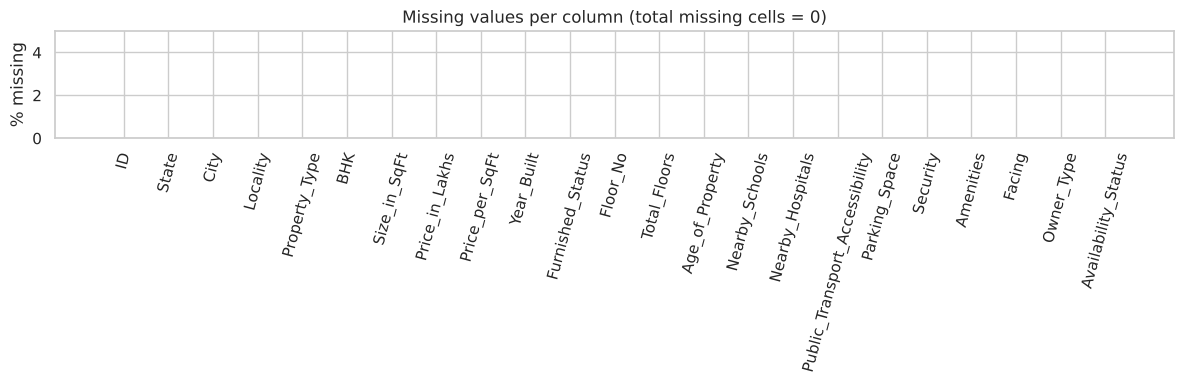

In [8]:
# Visualizing the missing values
fig, ax = plt.subplots(figsize=(12, 4))
missing_pct = raw_df.isnull().mean() * 100
ax.bar(missing_pct.index, missing_pct.values, color=PRIMARY)
ax.set_ylim(0, 5)
ax.set_ylabel("% missing")
ax.set_title(f"Missing values per column (total missing cells = {raw_df.isnull().sum().sum()})")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

In [9]:
# Data-quality checks beyond nulls
impossible_floor = (raw_df["Floor_No"] > raw_df["Total_Floors"]).mean() * 100
ppsf_check = (raw_df["Price_in_Lakhs"] / raw_df["Size_in_SqFt"] - raw_df["Price_per_SqFt"]).abs().max()
print(f"Rows where Floor_No > Total_Floors : {impossible_floor:.1f} %")
print(f"Price_per_SqFt unit                : lakhs / sq ft, rounded to 2 decimals (max rounding error {ppsf_check:.4f} lakh)")
print("Age_of_Property == 2025 - Year_Built:", (2025 - raw_df["Year_Built"] == raw_df["Age_of_Property"]).all())

Rows where Floor_No > Total_Floors : 46.5 %
Price_per_SqFt unit                : lakhs / sq ft, rounded to 2 decimals (max rounding error 0.0050 lakh)
Age_of_Property == 2025 - Year_Built: True


### What did you know about your dataset?

* The dataset has **250,000 property listings and 23 columns** covering 20 states, 42 cities and 500 localities.
* There are **no missing values and no duplicate rows / IDs**, so no imputation is needed (the pipeline still contains median/mode imputation in case new data arrives with gaps).
* **Data-quality issues found:**
  * In **46.5 % of rows `Floor_No` > `Total_Floors`**, which is impossible; these look like swapped entries.
  * `Price_per_SqFt` is stored in **lakhs per sq ft rounded to two decimals** (0.10 = ₹10,000), so most of its precision is lost; it must be recomputed.
  * `Age_of_Property` is consistently `2025 - Year_Built`, which gives us the reference year.
* 11 columns are numeric and 12 are categorical; `Amenities` is a comma-separated multi-value text field that needs to be split.

## ***2. Understanding Your Variables***

In [10]:
# Dataset Columns
raw_df.columns.tolist()

['ID',
 'State',
 'City',
 'Locality',
 'Property_Type',
 'BHK',
 'Size_in_SqFt',
 'Price_in_Lakhs',
 'Price_per_SqFt',
 'Year_Built',
 'Furnished_Status',
 'Floor_No',
 'Total_Floors',
 'Age_of_Property',
 'Nearby_Schools',
 'Nearby_Hospitals',
 'Public_Transport_Accessibility',
 'Parking_Space',
 'Security',
 'Amenities',
 'Facing',
 'Owner_Type',
 'Availability_Status']

In [11]:
# Dataset Describe
raw_df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
ID,250000.0,125000.50,72168.93,1.0,62500.75,125000.50,187500.25,250000.00
BHK,250000.0,3.00,1.42,1.0,2.00,3.00,4.00,5.00
Size_in_SqFt,250000.0,2749.81,1300.61,500.0,1623.00,2747.00,3874.00,5000.00
Price_in_Lakhs,250000.0,254.59,141.35,10.0,132.55,253.87,376.88,500.00
Price_per_SqFt,250000.0,0.13,0.13,0.0,0.05,0.09,0.16,0.99
Year_Built,250000.0,2006.52,9.81,1990.0,1998.00,2007.00,2015.00,2023.00
Floor_No,250000.0,14.97,8.95,0.0,7.00,15.00,23.00,30.00
Total_Floors,250000.0,15.50,8.67,1.0,8.00,15.00,23.00,30.00
Age_of_Property,250000.0,18.48,9.81,2.0,10.00,18.00,27.00,35.00
Nearby_Schools,250000.0,5.50,2.88,1.0,3.00,5.00,8.00,10.00


### Variables Description

| Variable | Type | Description |
|---|---|---|
| ID | int | Unique identifier for each property |
| State / City / Locality | categorical | Location of the property (20 / 42 / 500 unique values) |
| Property_Type | categorical | Apartment, Independent House or Villa |
| BHK | int (1-5) | Number of bedrooms-hall-kitchen |
| Size_in_SqFt | int (500-5,000) | Built-up area |
| Price_in_Lakhs | float (10-500) | Listed price in ₹ lakhs |
| Price_per_SqFt | float | Price ÷ area, in lakhs (rebuilt in ₹ as `Price_per_SqFt_Rs`) |
| Year_Built | int (1990-2023) | Construction year |
| Furnished_Status | categorical | Unfurnished / Semi-furnished / Furnished |
| Floor_No / Total_Floors | int | Floor of the unit and floors in the building |
| Age_of_Property | int | 2025 − Year_Built |
| Nearby_Schools / Nearby_Hospitals | int (1-10) | Count/rating of schools and hospitals nearby |
| Public_Transport_Accessibility | categorical | Low / Medium / High |
| Parking_Space / Security | Yes/No | Availability of parking and security |
| Amenities | text | Comma-separated list from Gym, Pool, Garden, Clubhouse, Playground |
| Facing | categorical | North / South / East / West |
| Owner_Type | categorical | Owner / Builder / Broker |
| Availability_Status | categorical | Ready_to_Move / Under_Construction |

### Check Unique Values for each variable.

In [12]:
# Check Unique Values for each variable.
for col in raw_df.columns:
    print(f"{col:<32} {raw_df[col].nunique():>7,} unique")

ID                               250,000 unique
State                                 20 unique
City                                  42 unique
Locality                             500 unique
Property_Type                          3 unique
BHK                                    5 unique
Size_in_SqFt                       4,501 unique
Price_in_Lakhs                    48,700 unique
Price_per_SqFt                       100 unique
Year_Built                            34 unique
Furnished_Status                       3 unique
Floor_No                              31 unique
Total_Floors                          30 unique
Age_of_Property                       34 unique
Nearby_Schools                        10 unique
Nearby_Hospitals                      10 unique
Public_Transport_Accessibility         3 unique
Parking_Space                          2 unique
Security                               2 unique
Amenities                            325 unique
Facing                                 4

## 3. ***Data Wrangling***

### Data Wrangling Code

In [13]:
# Write your code to make your dataset analysis ready.
# The logic lives in src/data_preprocessing.py so the notebook, the training
# script and the Streamlit app all use exactly the same transformations.

# Step 1 - cleaning: duplicates, imputation, floor fix, precise price/sqft, IQR capping
df = clean_data(raw_df)

# Step 2 - market benchmark: median price and price/sqft for every city
city_stats = build_city_reference_stats(df)

# Step 3 - feature engineering: amenity flags, infrastructure & school scores,
#          city tier and price relative to the city median
df = engineer_features(df, city_stats)

# Step 4 - targets: Expected_Growth_Rate, Future_Price_5Y_Lakhs, Investment_Score, Good_Investment
df = create_targets(df)

print("Shape after wrangling:", df.shape)
print("Floor_No > Total_Floors after fix:", (df["Floor_No"] > df["Total_Floors"]).sum())
print(f"Good_Investment share: {df['Good_Investment'].mean():.1%}")
df[["City", "City_Tier", "Price_in_Lakhs", "Price_per_SqFt_Rs", "Infrastructure_Score",
    "Amenities_Count", "PPSF_vs_City_Median", "Expected_Growth_Rate",
    "Future_Price_5Y_Lakhs", "Investment_Score", "Good_Investment"]].head()

INFO | Duplicates removed: 0 full-row, 0 repeated IDs


INFO | Missing values imputed: 0


INFO | Rows with Floor_No > Total_Floors fixed by swapping: 116304


INFO | Outliers capped in Price_in_Lakhs    : 0


INFO | Outliers capped in Size_in_SqFt      : 0


INFO | Outliers capped in Price_per_SqFt_Rs : 19723


Shape after wrangling: (250000, 42)
Floor_No > Total_Floors after fix: 0
Good_Investment share: 54.8%


,City,City_Tier,Price_in_Lakhs,Price_per_SqFt_Rs,Infrastructure_Score,Amenities_Count,PPSF_vs_City_Median,Expected_Growth_Rate,Future_Price_5Y_Lakhs,Investment_Score,Good_Investment
0,Chennai,Tier 1,489.76,10332.49,7.55,5,1.1076,0.0936,766.08,5.0,0
1,Pune,Tier 1,195.52,8270.73,3.15,5,0.8671,0.0904,301.38,6.5,1
2,Ludhiana,Tier 2,183.79,5046.40,5.95,4,0.5512,0.0753,264.22,6.5,1
3,Jodhpur,Tier 2,300.29,10955.49,7.20,5,1.1819,0.0892,460.34,6.0,1
4,Jaipur,Tier 2,182.90,3792.25,4.55,5,0.4171,0.0679,254.02,6.5,1


In [14]:
# Save the analysis-ready dataset (same file the model training uses)
cfg.PROCESSED_DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(cfg.PROCESSED_DATA_PATH, index=False)
city_stats.to_csv(cfg.CITY_STATS_PATH, index=False)
print("Saved:", cfg.PROCESSED_DATA_PATH.relative_to(ROOT))

Saved: data/processed/cleaned_housing_data.csv


### What all manipulations have you done and insights you found?

**Manipulations**

1. **Duplicates / missing values** – checked (none found); median / mode imputation is in place for future data.
2. **Floor inconsistency** – 116,304 rows had `Floor_No > Total_Floors`; the two values were swapped back.
3. **Precise price per sq ft** – rebuilt as `Price_per_SqFt_Rs = Price_in_Lakhs × 1,00,000 ÷ Size_in_SqFt`.
4. **Outliers** – IQR rule on price, size and price/sq ft. Only price/sq ft had outliers (19,723 rows above ≈ ₹32,764), which were **capped**, not dropped.
5. **New features**
   * `Has_Gym … Has_Playground`, `Amenities_Count` – from the multi-value amenities text.
   * `Parking_Flag`, `Security_Flag`, `Ready_To_Move_Flag` – binary encodings.
   * `City_Tier` – Tier 1 metros, Tier 2 and Tier 3 cities.
   * `Infrastructure_Score` (0-10) – schools 35 % + hospitals 35 % + transport 30 %.
   * `School_Density_Score` (0-10) – nearby schools rescaled.
   * `PPSF_vs_City_Median`, `Price_vs_City_Median` – how expensive the listing is relative to its own city.
6. **Targets**
   * `Future_Price_5Y_Lakhs = Price × (1 + r)^5`, with *r* = 8 % base ± adjustments for tier, transport, infrastructure, under-construction premium, property type, age and amenities, plus N(0, 0.5 %) market noise.
   * `Good_Investment = 1` when the multi-factor `Investment_Score` (0-10) ≥ 5.5.

**Insights**

* After cleaning, 54.8 % of listings qualify as good investments, so the classification target is well balanced.
* Expected annual appreciation ranges from about 3.7 % to 12.9 % (mean 8.6 %), i.e. a property grows to roughly **1.2× – 1.8×** its value in five years.
* The brief mentions *crime rate*, *RERA* and an *infrastructure score*; crime rate and RERA are **not in the dataset**, so the infrastructure score was engineered from the available schools, hospitals and transport columns.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

Charts follow the **UBM** rule: **Univariate (Charts 1-5) → Bivariate (Charts 6-20) → Multivariate (Charts 21-25)**.
All 20 EDA questions from the project brief are answered; the matching question number is shown in each title as *(Brief Q#)*.

### U - Univariate Analysis

#### Chart - 1 : Distribution of property prices (Brief Q1)

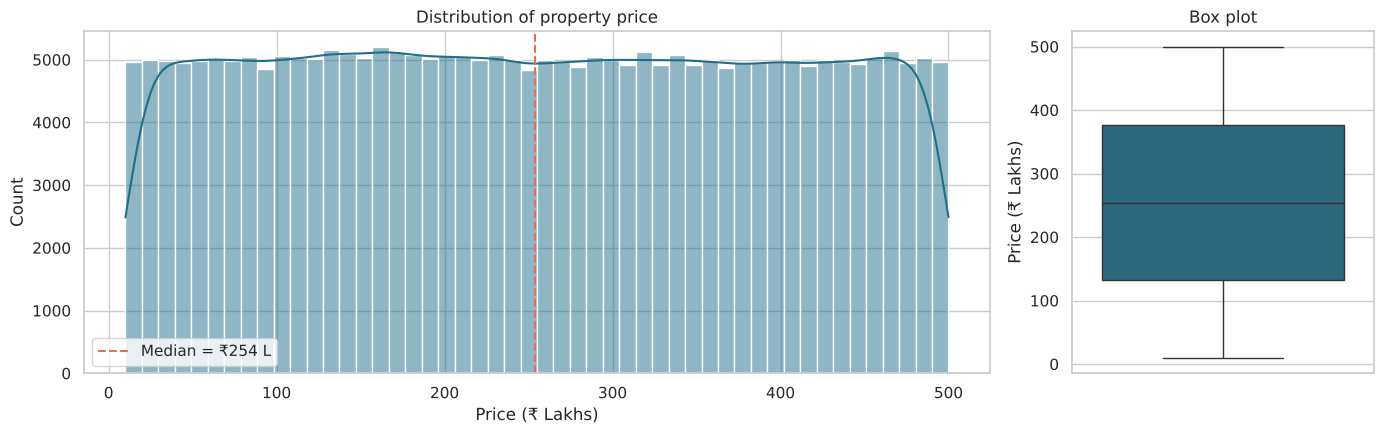

count    250000.0
mean        254.6
std         141.3
min          10.0
25%         132.6
50%         253.9
75%         376.9
max         500.0
Name: Price_in_Lakhs, dtype: float64
Skewness: 0.008


In [15]:
# Chart - 1 visualization code
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [3, 1]})
sns.histplot(df["Price_in_Lakhs"], bins=50, kde=True, color=PRIMARY, ax=axes[0])
axes[0].axvline(df["Price_in_Lakhs"].median(), color=BAD, ls="--",
                label=f"Median = ₹{df['Price_in_Lakhs'].median():.0f} L")
axes[0].set(title="Distribution of property price", xlabel="Price (₹ Lakhs)")
axes[0].legend()
sns.boxplot(y=df["Price_in_Lakhs"], color=PRIMARY, ax=axes[1])
axes[1].set(title="Box plot", ylabel="Price (₹ Lakhs)")
plt.tight_layout(); plt.show()
print(df["Price_in_Lakhs"].describe().round(1)); print("Skewness:", round(df["Price_in_Lakhs"].skew(), 3))

##### 1. Why did you pick the specific chart?

A histogram with KDE shows the full shape of a continuous variable, and the side box plot adds the median, spread and outliers in one glance — the right first look at the target-related variable.

##### 2. What is/are the insight(s) found from the chart?

* Prices are spread **almost uniformly between ₹10 L and ₹500 L** (skewness ≈ 0), with a median of about ₹254 L and an inter-quartile range of ₹133-377 L.
* There are no extreme price outliers; the market in this data is evenly spread across budget, mid and premium segments.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** an even spread means every budget segment has plenty of supply, so a platform can serve first-time buyers and premium investors equally and the models see enough examples at every price level.
**Negative:** the absence of a natural price "cluster" means price alone says little about value; investors who judge by the sticker price risk overpaying, which is why the advisor compares each price with its city median.

#### Chart - 2 : Distribution of property sizes (Brief Q2)

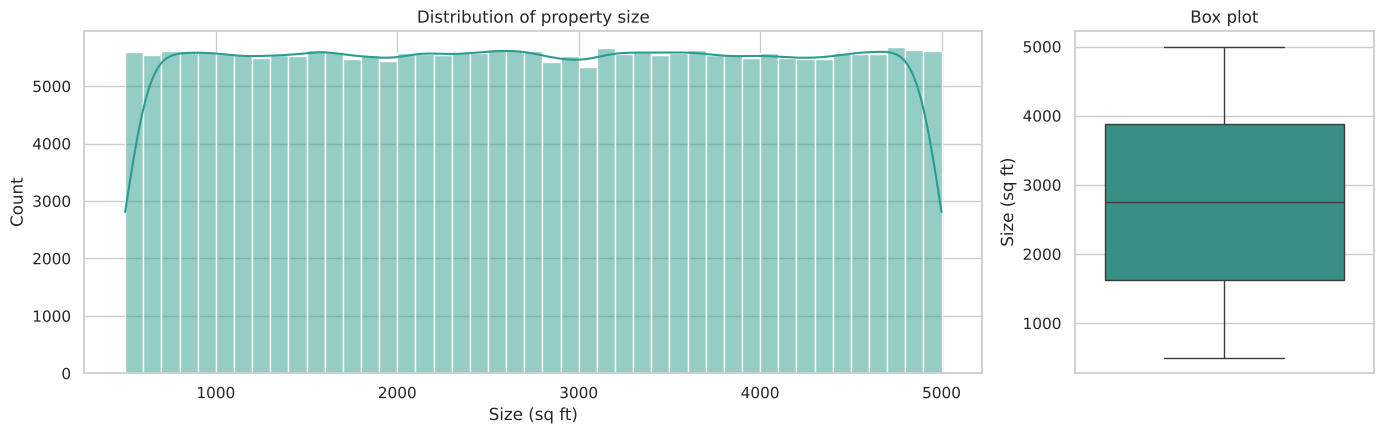

count    250000.0
mean       2750.0
std        1301.0
min         500.0
25%        1623.0
50%        2747.0
75%        3874.0
max        5000.0
Name: Size_in_SqFt, dtype: float64


In [16]:
# Chart - 2 visualization code
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [3, 1]})
sns.histplot(df["Size_in_SqFt"], bins=45, kde=True, color=GOOD, ax=axes[0])
axes[0].set(title="Distribution of property size", xlabel="Size (sq ft)")
sns.boxplot(y=df["Size_in_SqFt"], color=GOOD, ax=axes[1])
axes[1].set(title="Box plot", ylabel="Size (sq ft)")
plt.tight_layout(); plt.show()
print(df["Size_in_SqFt"].describe().round(0))

##### 1. Why did you pick the specific chart?

Same reasoning as Chart 1: a histogram + box plot is the clearest way to see the range, centre and spread of a continuous variable such as area.

##### 2. What is/are the insight(s) found from the chart?

* Sizes range from **500 to 5,000 sq ft**, again almost uniformly distributed (median ≈ 2,750 sq ft, IQR 1,620-3,870 sq ft).
* No size outliers were detected by the IQR rule.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** inventory exists for compact flats as well as large villas, so recommendations can be made across buyer profiles (singles, families, luxury buyers).
**Negative:** because size is spread evenly but prices are not linked to size (see Chart 7), large homes are not systematically priced higher — buyers of small units can end up paying very high rates per sq ft.

#### Chart - 3 : Outliers in price per sq ft and property size (Brief Q5)

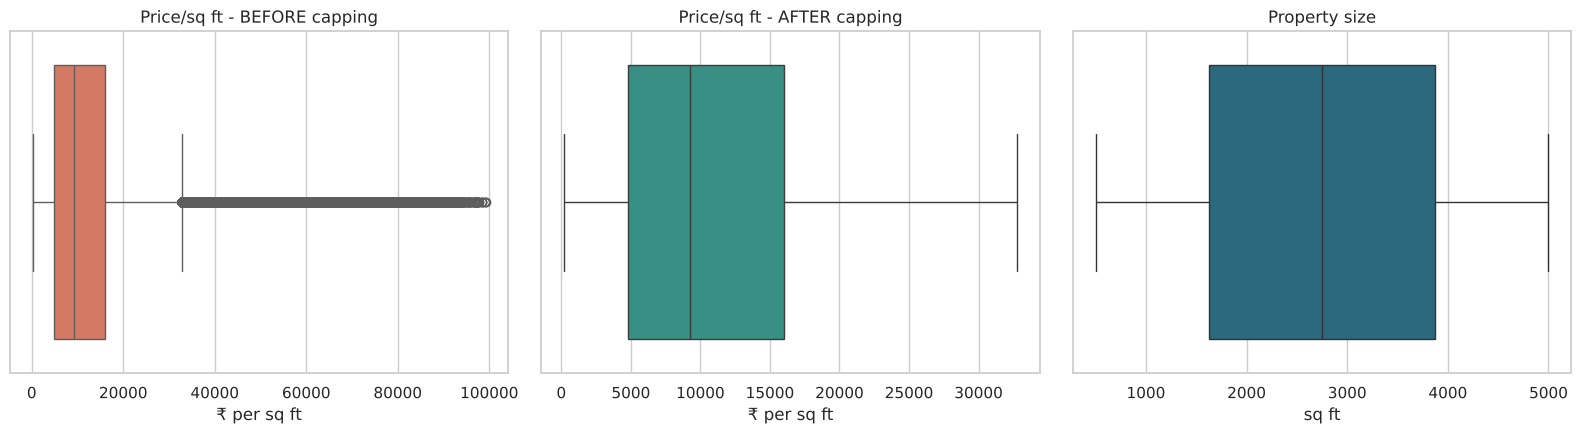

IQR upper fence for price/sq ft: ₹32,764  ->  outliers: 19,723 (7.9%)
Max raw price/sq ft: ₹99,182


In [17]:
# Chart - 3 visualization code
raw_ppsf = raw_df["Price_in_Lakhs"] * 1e5 / raw_df["Size_in_SqFt"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.boxplot(x=raw_ppsf, color=BAD, ax=axes[0]);          axes[0].set(title="Price/sq ft - BEFORE capping", xlabel="₹ per sq ft")
sns.boxplot(x=df["Price_per_SqFt_Rs"], color=GOOD, ax=axes[1]); axes[1].set(title="Price/sq ft - AFTER capping", xlabel="₹ per sq ft")
sns.boxplot(x=df["Size_in_SqFt"], color=PRIMARY, ax=axes[2]);  axes[2].set(title="Property size", xlabel="sq ft")
plt.tight_layout(); plt.show()
q1, q3 = raw_ppsf.quantile([.25, .75]); upper = q3 + 1.5 * (q3 - q1)
print(f"IQR upper fence for price/sq ft: ₹{upper:,.0f}  ->  outliers: {(raw_ppsf > upper).sum():,} ({(raw_ppsf > upper).mean():.1%})")
print(f"Max raw price/sq ft: ₹{raw_ppsf.max():,.0f}")

##### 1. Why did you pick the specific chart?

Box plots are the standard tool for outlier detection because the whiskers mark the 1.5 × IQR fences directly; showing *before vs after* proves the treatment worked.

##### 2. What is/are the insight(s) found from the chart?

* **Price per sq ft is heavily right-skewed**: 19,723 listings (7.9 %) lie above the IQR fence of ≈ ₹32,800/sq ft, with a maximum near ₹99,000/sq ft. These are small units carrying very high prices.
* **Property size has no outliers.**
* After capping, the price/sq ft distribution is compact and usable for modelling without losing any listings.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** capping instead of deleting keeps every listing while stopping a few extreme values from distorting averages and model training.
**Negative:** the extreme listings are themselves a warning sign — a buyer paying ₹50,000+/sq ft in a city whose median is ≈ ₹9,200/sq ft is likely overpaying, and such listings are rightly scored low by the advisor.

#### Chart - 4 : Properties by owner type (Brief Q16)

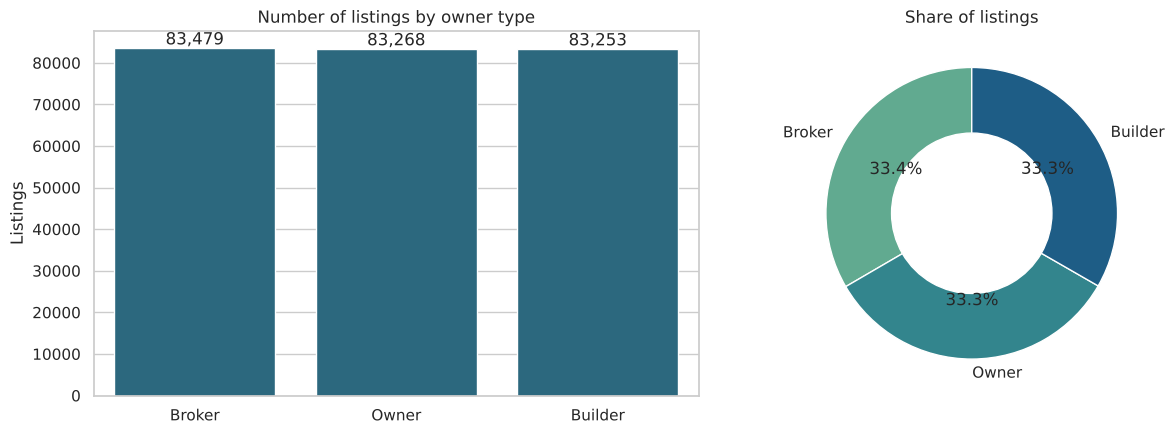

In [18]:
# Chart - 4 visualization code
counts = df["Owner_Type"].value_counts()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.countplot(data=df, x="Owner_Type", order=counts.index, color=PRIMARY, ax=axes[0])
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()),
                     ha="center", va="bottom")
axes[0].set(title="Number of listings by owner type", xlabel="", ylabel="Listings")
axes[1].pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=90,
            colors=sns.color_palette("crest", 3), wedgeprops={"width": 0.45})
axes[1].set_title("Share of listings")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A count plot gives exact numbers per category and a donut chart shows the share — together they answer 'how many' and 'what proportion'.

##### 2. What is/are the insight(s) found from the chart?

* Listings are split **almost exactly in thirds**: Broker ≈ 83.5k, Owner ≈ 83.3k, Builder ≈ 83.3k.
* No single channel dominates supply.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** a platform can partner with all three channels; one third of inventory comes directly from owners, which allows broker-free deals and lower transaction cost for buyers.
**Negative:** a third of listings come through brokers, adding commission (typically 1-2 %) that reduces the investor's net return; this cost is not visible in the listed price.

#### Chart - 5 : Properties by availability status (Brief Q17)

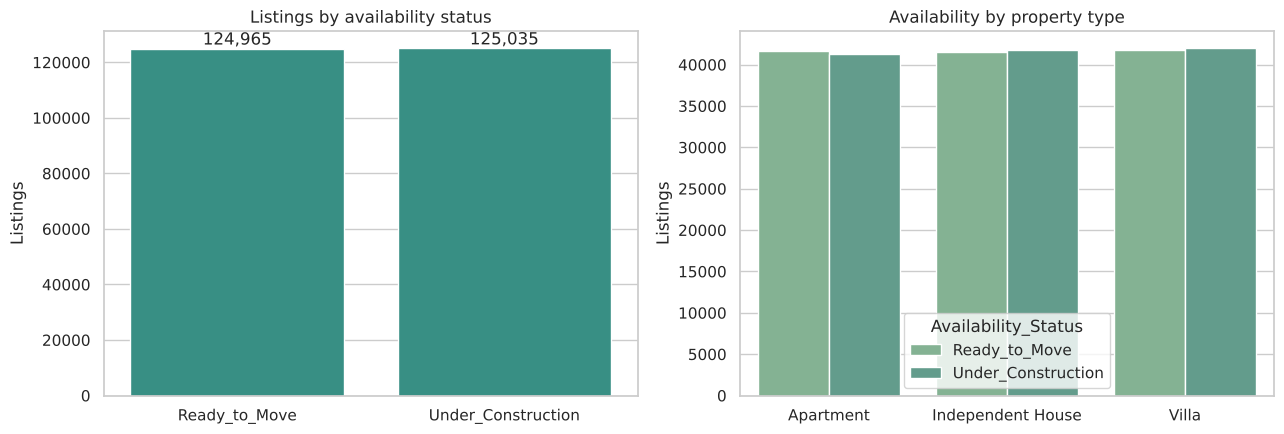

In [19]:
# Chart - 5 visualization code
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.countplot(data=df, x="Availability_Status", color=GOOD, ax=axes[0])
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()),
                     ha="center", va="bottom")
axes[0].set(title="Listings by availability status", xlabel="", ylabel="Listings")
sns.countplot(data=df, x="Property_Type", hue="Availability_Status", ax=axes[1])
axes[1].set(title="Availability by property type", xlabel="", ylabel="Listings")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A count plot is ideal for a categorical variable; splitting it by property type adds context without clutter.

##### 2. What is/are the insight(s) found from the chart?

* Supply is split **50/50 between Ready-to-Move (124,965) and Under-Construction (125,035)** listings.
* The split is the same for apartments, independent houses and villas. (The brief also mentions a *Sold* status, but it does not appear in the data.)

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** half the market is under construction, which typically carries an appreciation premium on completion — our growth assumptions add +1 % per year for these properties.
**Negative:** under-construction property carries delivery and builder risk (delays, stalled projects); that is why ready-to-move listings receive a point in the investment score and have a higher good-investment rate (61 % vs 48 %, see Chart 23).

### B - Bivariate Analysis

#### Chart - 6 : Price per sq ft by property type (Brief Q3)

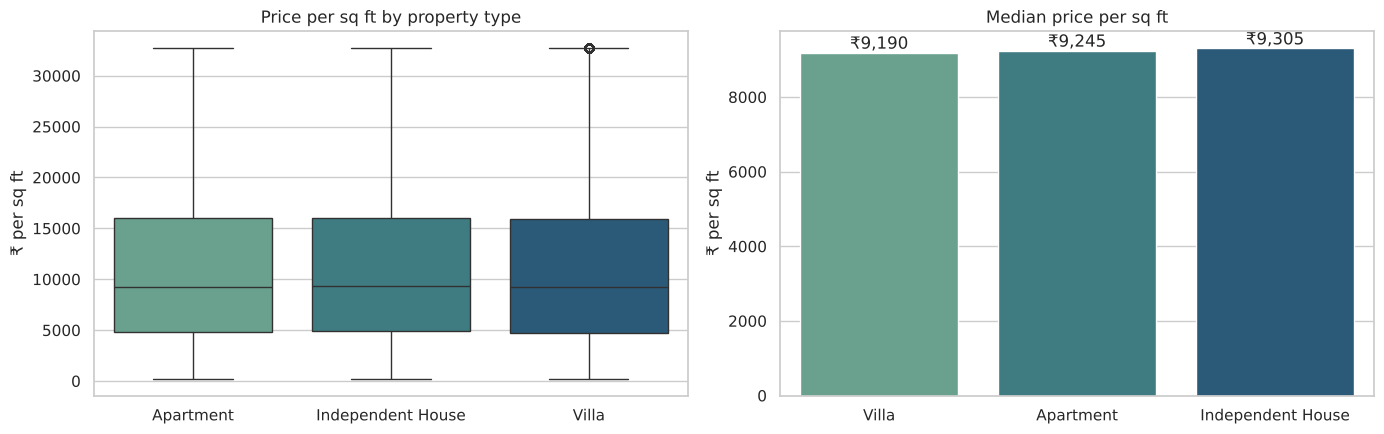

In [20]:
# Chart - 6 visualization code
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=df, x="Property_Type", y="Price_per_SqFt_Rs", palette="crest", ax=axes[0])
axes[0].set(title="Price per sq ft by property type", xlabel="", ylabel="₹ per sq ft")
med = df.groupby("Property_Type")["Price_per_SqFt_Rs"].median().sort_values()
sns.barplot(x=med.index, y=med.values, palette="crest", ax=axes[1])
for i, v in enumerate(med.values):
    axes[1].text(i, v, f"₹{v:,.0f}", ha="center", va="bottom")
axes[1].set(title="Median price per sq ft", xlabel="", ylabel="₹ per sq ft")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

Numerical vs categorical comparison: box plots compare whole distributions across property types, and the bar chart makes the medians easy to read.

##### 2. What is/are the insight(s) found from the chart?

* Median price per sq ft is **virtually identical** across types: Villa ≈ ₹9,190, Apartment ≈ ₹9,245, Independent House ≈ ₹9,305.
* A one-way ANOVA confirms the difference is not significant (p ≈ 0.20).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** villas and independent houses (which give land ownership and more privacy) are available at the **same rate per sq ft as apartments**, making them relatively better value — the growth model gives them a small appreciation premium.
**Negative:** because the market doesn't price property type, sellers of apartments are not discounting for the lack of land, so apartment buyers get less for the same rate.

#### Chart - 7 : Relationship between property size and price (Brief Q4)

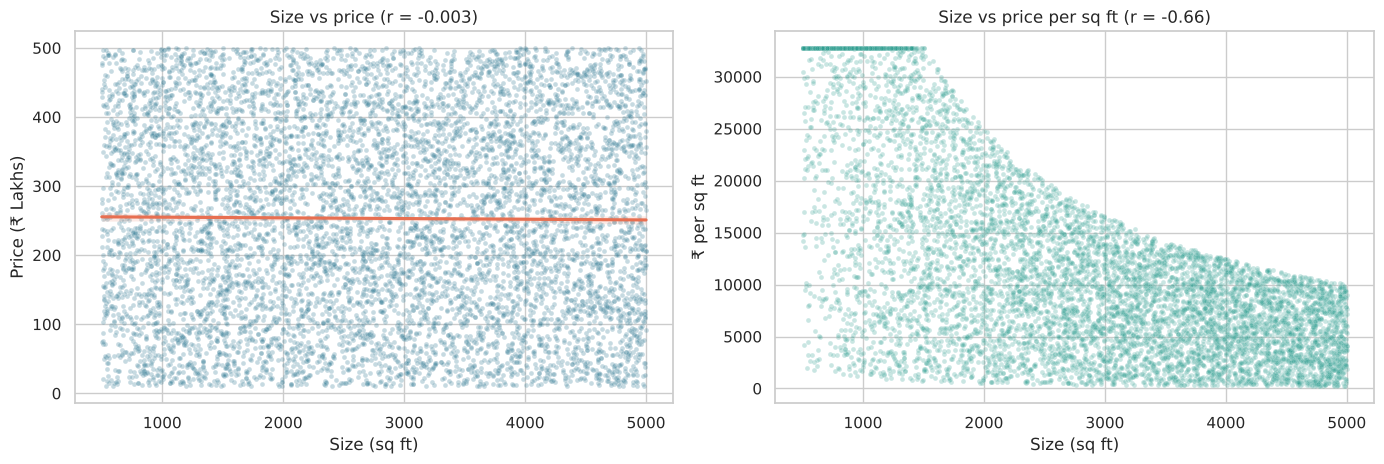

In [21]:
# Chart - 7 visualization code
sample = df.sample(8000, random_state=42)        # sample for readability
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.scatterplot(data=sample, x="Size_in_SqFt", y="Price_in_Lakhs", alpha=0.25, s=12, color=PRIMARY, ax=axes[0])
sns.regplot(data=sample, x="Size_in_SqFt", y="Price_in_Lakhs", scatter=False, color=BAD, ax=axes[0])
axes[0].set(title=f"Size vs price (r = {df['Size_in_SqFt'].corr(df['Price_in_Lakhs']):.3f})",
            xlabel="Size (sq ft)", ylabel="Price (₹ Lakhs)")
sns.scatterplot(data=sample, x="Size_in_SqFt", y="Price_per_SqFt_Rs", alpha=0.25, s=12, color=GOOD, ax=axes[1])
axes[1].set(title=f"Size vs price per sq ft (r = {df['Size_in_SqFt'].corr(df['Price_per_SqFt_Rs']):.2f})",
            xlabel="Size (sq ft)", ylabel="₹ per sq ft")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

Numerical vs numerical: a scatter plot with a fitted regression line is the standard way to inspect the direction and strength of a relationship.

##### 2. What is/are the insight(s) found from the chart?

* **Size and price are uncorrelated (r ≈ -0.003)** — a 5,000 sq ft villa is, on average, no more expensive than a 500 sq ft flat.
* As a result, **price per sq ft falls sharply as size increases (r ≈ -0.66)**: small units carry very high per-sq-ft rates.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** larger properties offer far more space per rupee; investors targeting rental yield or family buyers get the best value in large units, and the PPSF-vs-city-median feature captures exactly this.
**Negative:** small units are frequently overpriced on a per-sq-ft basis, so buyers of compact flats risk overpaying and seeing weaker returns.

#### Chart - 8 : Average price per sq ft by state (Brief Q6)

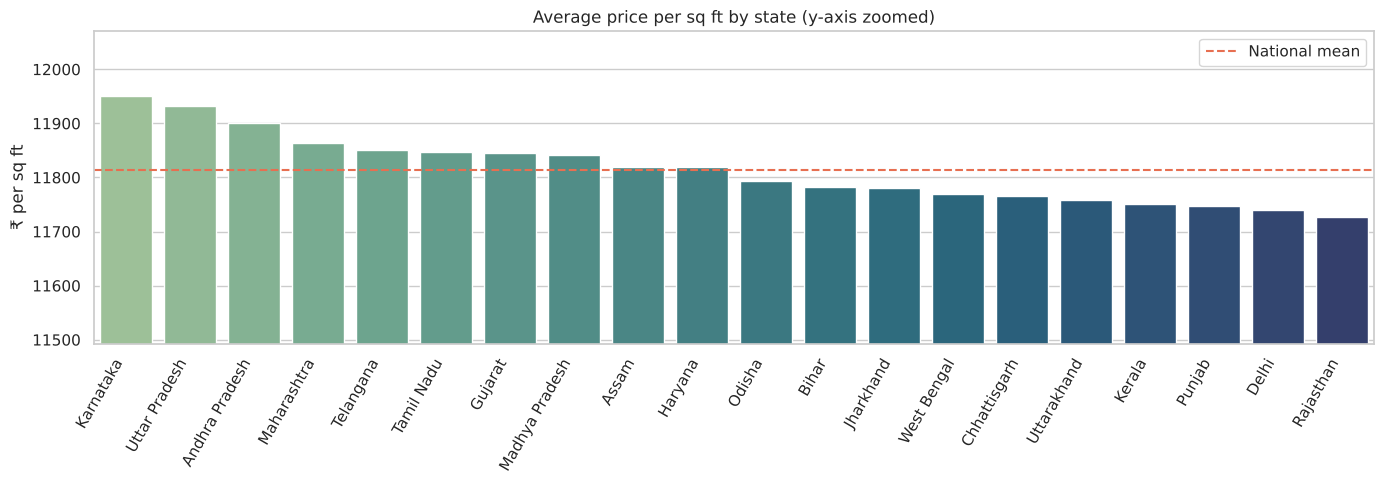

Spread between highest and lowest state: 1.9%


In [22]:
# Chart - 8 visualization code
state_ppsf = df.groupby("State")["Price_per_SqFt_Rs"].mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(14, 5))
sns.barplot(x=state_ppsf.index, y=state_ppsf.values, palette="crest", ax=ax)
ax.axhline(df["Price_per_SqFt_Rs"].mean(), color=BAD, ls="--", label="National mean")
ax.set_ylim(state_ppsf.min() * 0.98, state_ppsf.max() * 1.01)    # zoom in to show differences
ax.set(title="Average price per sq ft by state (y-axis zoomed)", xlabel="", ylabel="₹ per sq ft")
ax.legend(); plt.xticks(rotation=60, ha="right"); plt.tight_layout(); plt.show()
print(f"Spread between highest and lowest state: {(state_ppsf.max() / state_ppsf.min() - 1):.1%}")

##### 1. Why did you pick the specific chart?

A sorted bar chart compares one metric across many categories; the zoomed y-axis makes small differences visible (and is clearly labelled).

##### 2. What is/are the insight(s) found from the chart?

* Karnataka (≈ ₹11,950), Uttar Pradesh and Andhra Pradesh have the highest average price per sq ft; Rajasthan (≈ ₹11,730), Delhi and Punjab the lowest.
* The total spread between the most and least expensive state is only **≈ 1.9 %** — state-level pricing is almost flat.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** with near-identical pricing everywhere, investors can choose states on **growth fundamentals** (tier, infrastructure, transport) rather than entry price; states with strong Tier-1 cities offer higher expected appreciation for the same rate.
**Negative:** flat pricing also means there is no "cheap state" bargain to exploit; an investor expecting lower prices in smaller states will not find them in this data.

#### Chart - 9 : Average property price by city (Brief Q7)

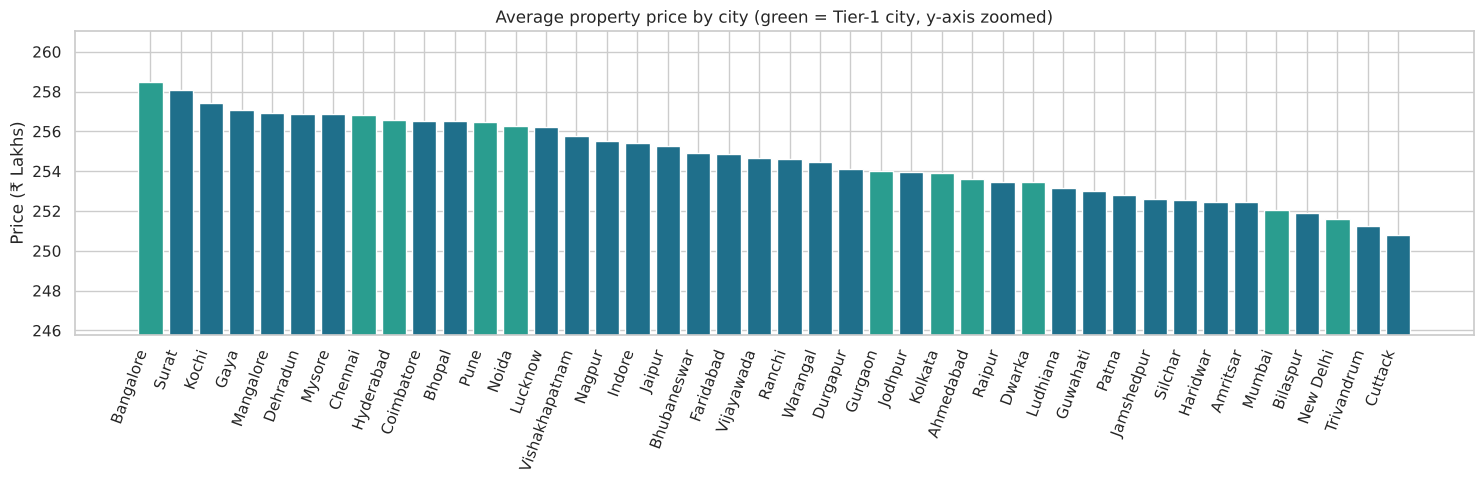

City
Bangalore    258.5
Surat        258.1
Kochi        257.4
Name: Price_in_Lakhs, dtype: float64
City
New Delhi     251.6
Trivandrum    251.3
Cuttack       250.8
Name: Price_in_Lakhs, dtype: float64


In [23]:
# Chart - 9 visualization code
city_price = df.groupby("City")["Price_in_Lakhs"].mean().sort_values(ascending=False)
colors = [GOOD if c in cfg.TIER_1_CITIES else PRIMARY for c in city_price.index]
fig, ax = plt.subplots(figsize=(15, 5))
ax.bar(city_price.index, city_price.values, color=colors)
ax.set_ylim(city_price.min() * 0.98, city_price.max() * 1.01)
ax.set(title="Average property price by city (green = Tier-1 city, y-axis zoomed)", ylabel="Price (₹ Lakhs)")
plt.xticks(rotation=70, ha="right"); plt.tight_layout(); plt.show()
print(city_price.head(3).round(1)); print(city_price.tail(3).round(1))

##### 1. Why did you pick the specific chart?

A sorted bar chart ranks the 42 cities; colouring Tier-1 cities shows whether metro status drives price.

##### 2. What is/are the insight(s) found from the chart?

* Bangalore (≈ ₹258.5 L), Surat and Kochi have the highest average prices; Cuttack (≈ ₹250.8 L), Trivandrum and New Delhi the lowest.
* The gap between the most and least expensive city is just **≈ 3 %**, and Tier-1 cities are scattered across the ranking — metro status does not raise prices here.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** Tier-1 cities such as Bangalore, Hyderabad, Pune or Mumbai offer higher expected appreciation (+1 %/yr in our model) at practically the same entry price as Tier-3 cities, which makes them attractive buys.
**Negative:** Tier-3 cities get no price discount despite weaker growth prospects, so investors there carry lower return potential for the same capital.

#### Chart - 10 : Median age of properties by locality (Brief Q8)

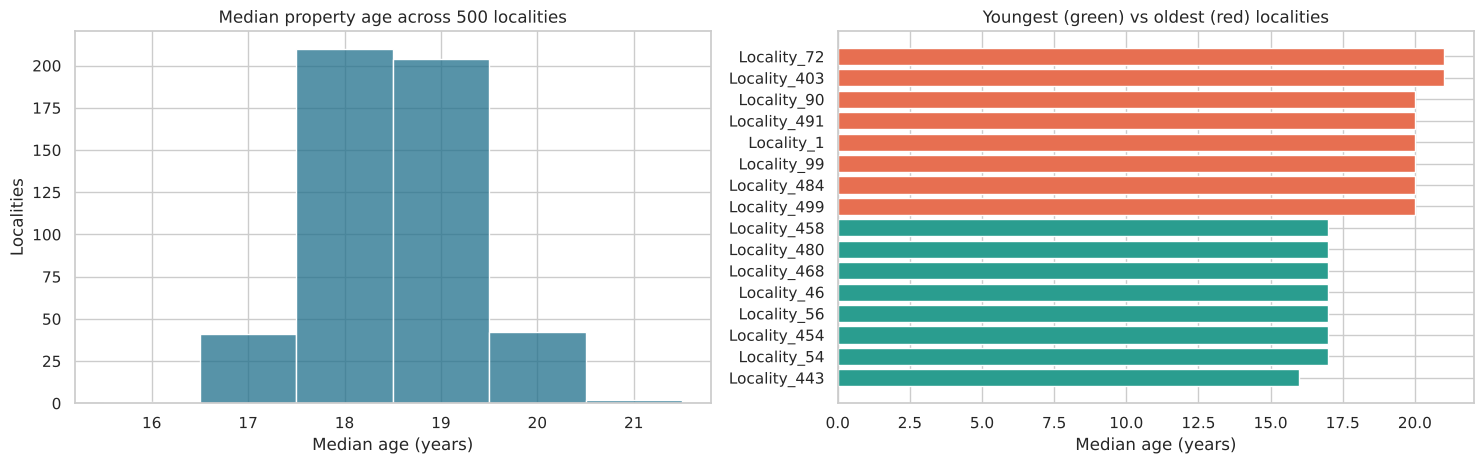

In [24]:
# Chart - 10 visualization code
loc_age = df.groupby("Locality")["Age_of_Property"].median().sort_values()
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
sns.histplot(loc_age, bins=range(15, 23), discrete=True, color=PRIMARY, ax=axes[0])
axes[0].set(title="Median property age across 500 localities", xlabel="Median age (years)", ylabel="Localities")
extremes = pd.concat([loc_age.head(8), loc_age.tail(8)])
axes[1].barh(extremes.index, extremes.values, color=[GOOD] * 8 + [BAD] * 8)
axes[1].set(title="Youngest (green) vs oldest (red) localities", xlabel="Median age (years)")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

With 500 localities a single bar chart is unreadable, so a histogram shows the overall distribution and a horizontal bar chart highlights the extremes.

##### 2. What is/are the insight(s) found from the chart?

* Most localities have a **median property age of 18-19 years**; the youngest localities have a median of about 16 years and the oldest about 21 years.
* Housing stock age is fairly similar across localities — there are no clearly "new-build" neighbourhoods.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** localities with younger stock need less maintenance and depreciate more slowly — our growth model reduces appreciation by 0.03 % per year of age, so younger localities score better.
**Negative:** much of the stock is 18+ years old; older buildings face higher repair costs and redevelopment uncertainty, which can drag down resale value.

#### Chart - 11 : BHK distribution across cities (Brief Q9)

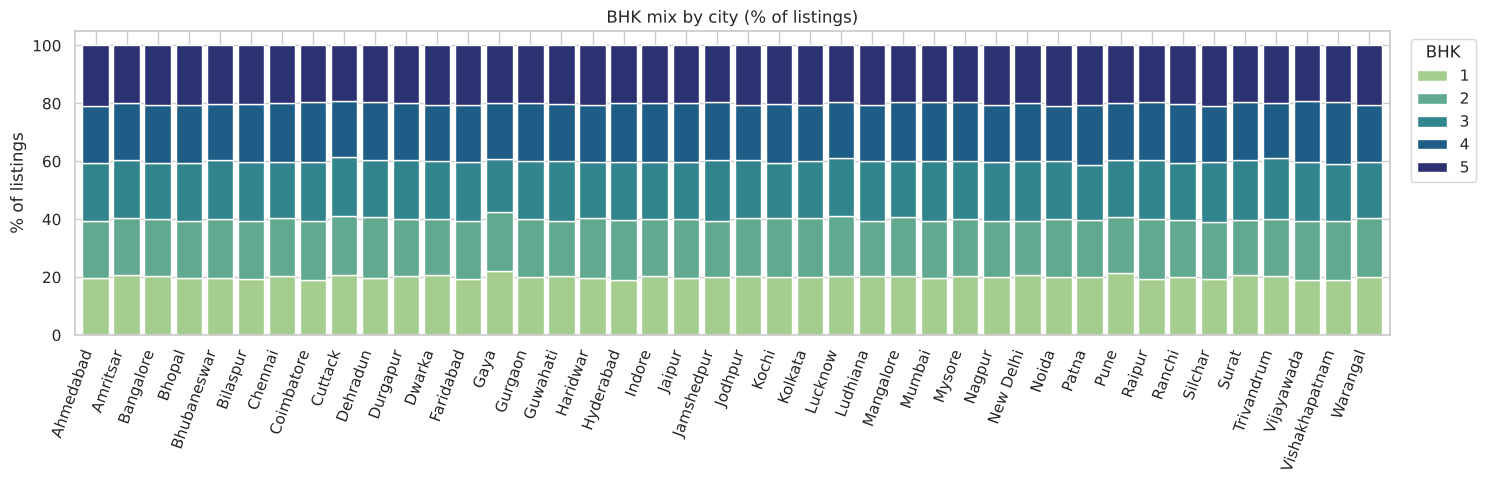

In [25]:
# Chart - 11 visualization code
bhk_city = pd.crosstab(df["City"], df["BHK"], normalize="index") * 100
fig, ax = plt.subplots(figsize=(15, 5))
bhk_city.plot(kind="bar", stacked=True, colormap="crest", ax=ax, width=0.85)
ax.set(title="BHK mix by city (% of listings)", xlabel="", ylabel="% of listings")
ax.legend(title="BHK", bbox_to_anchor=(1.01, 1))
plt.xticks(rotation=70, ha="right"); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

Categorical vs categorical: a 100 % stacked bar chart shows the composition (BHK mix) of every city on the same scale.

##### 2. What is/are the insight(s) found from the chart?

* Every city has an **even BHK mix of roughly 20 % each for 1-5 BHK** (city-level shares vary only between ≈ 19 % and 22 %).
* No city specialises in small or large units.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** buyers of any family size can find stock in every city. Since 3+ BHK homes earn a point in the investment score (62 % of 3-5 BHK listings are good investments vs 43 % of 1-2 BHK), investors can target larger units anywhere.
**Negative:** an even mix means 1-2 BHK units — which score lower — make up 40 % of supply in every city, so a large share of inventory is less attractive for long-term investment.

#### Chart - 12 : Price trends for the top 5 most expensive localities (Brief Q10)

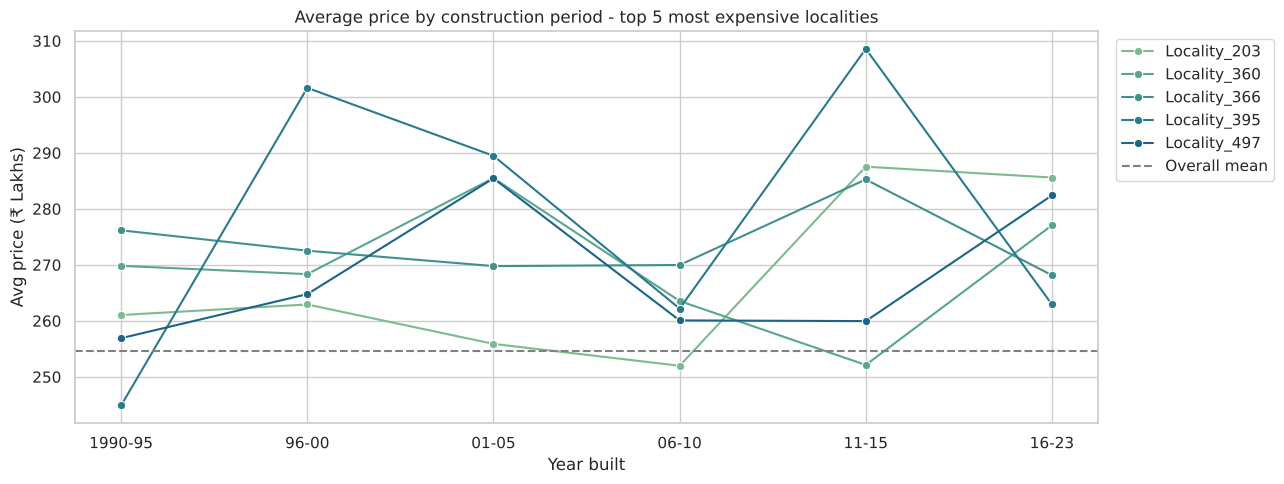

Locality
Locality_395    275.4
Locality_366    273.4
Locality_497    270.0
Locality_360    269.8
Locality_203    269.0
Name: Price_in_Lakhs, dtype: float64


In [26]:
# Chart - 12 visualization code
top5 = df.groupby("Locality")["Price_in_Lakhs"].mean().nlargest(5).index
trend = (df[df["Locality"].isin(top5)]
         .assign(Build_Period=lambda d: pd.cut(d["Year_Built"], bins=[1989, 1995, 2000, 2005, 2010, 2015, 2023],
                                               labels=["1990-95", "96-00", "01-05", "06-10", "11-15", "16-23"]))
         .groupby(["Build_Period", "Locality"], observed=True)["Price_in_Lakhs"].mean().reset_index())
fig, ax = plt.subplots(figsize=(13, 5))
sns.lineplot(data=trend, x="Build_Period", y="Price_in_Lakhs", hue="Locality", marker="o", ax=ax)
ax.axhline(df["Price_in_Lakhs"].mean(), color="grey", ls="--", label="Overall mean")
ax.set(title="Average price by construction period - top 5 most expensive localities",
       xlabel="Year built", ylabel="Avg price (₹ Lakhs)")
ax.legend(bbox_to_anchor=(1.01, 1)); plt.tight_layout(); plt.show()
print(df.groupby("Locality")["Price_in_Lakhs"].mean().nlargest(5).round(1))

##### 1. Why did you pick the specific chart?

The dataset has no transaction dates, so construction period is the only time axis; a multi-line chart compares the five localities' price trend over it.

##### 2. What is/are the insight(s) found from the chart?

* The top five localities (Locality_395 ≈ ₹275 L, 366, 497, 360, 203) average **₹269-275 L, about 6-8 % above the overall mean** of ₹255 L.
* Their prices **fluctuate between construction periods without a consistent upward or downward trend** — newer buildings are not systematically pricier.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** premium localities hold their price level across building ages, which suggests location (not newness) carries the premium — useful for investors seeking resale stability.
**Negative:** paying a 6-8 % premium for these localities does not buy better fundamentals in this data; if the premium is not backed by infrastructure or transport it can reduce future return.

#### Chart - 13 : Nearby schools vs price per sq ft (Brief Q12)

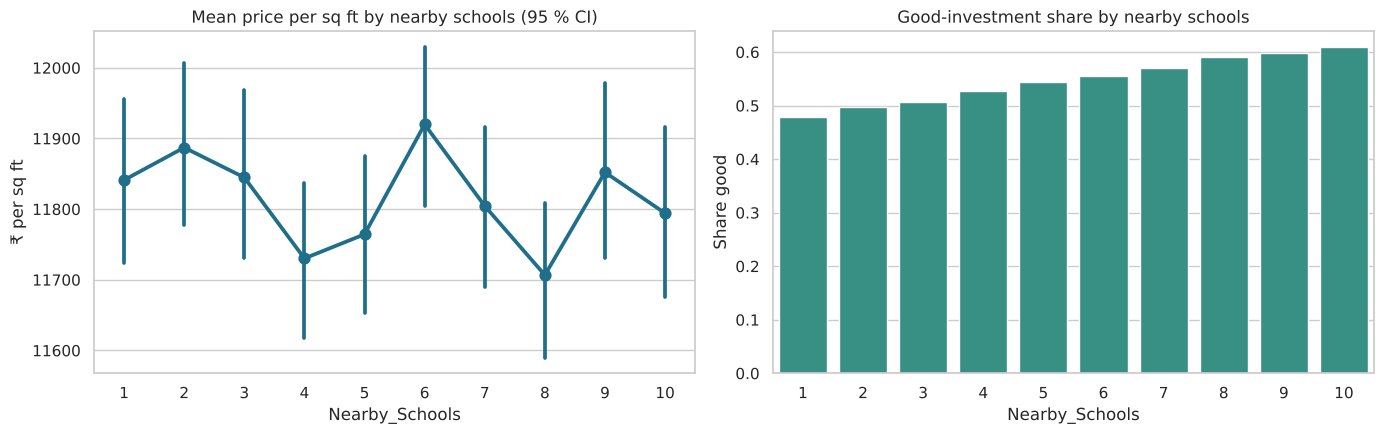

Correlation (schools, price/sqft): -0.0019


In [27]:
# Chart - 13 visualization code
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.pointplot(data=df, x="Nearby_Schools", y="Price_per_SqFt_Rs", color=PRIMARY, errorbar=("ci", 95), ax=axes[0])
axes[0].set(title="Mean price per sq ft by nearby schools (95 % CI)", ylabel="₹ per sq ft")
sns.barplot(data=df, x="Nearby_Schools", y="Good_Investment", color=GOOD, errorbar=None, ax=axes[1])
axes[1].set(title="Good-investment share by nearby schools", ylabel="Share good")
plt.tight_layout(); plt.show()
print("Correlation (schools, price/sqft):", round(df["Nearby_Schools"].corr(df["Price_per_SqFt_Rs"]), 4))

##### 1. Why did you pick the specific chart?

A point plot with confidence intervals tests whether the mean really changes with the number of schools; the second panel links schools to the investment label.

##### 2. What is/are the insight(s) found from the chart?

* Price per sq ft is **flat across 1-10 nearby schools** (all means ≈ ₹11,700-11,900 with overlapping confidence intervals; r ≈ 0).
* However, the **good-investment share rises with the number of schools**, because schools feed the infrastructure score.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** properties near many schools cost no more per sq ft, so families can get better access to education **without paying a premium** — a clear value opportunity, and such homes usually see stronger rental demand.
**Negative:** the market isn't rewarding school access in price yet, so investors should not assume a school-rich location will automatically command a higher resale price.

#### Chart - 14 : Nearby hospitals vs price per sq ft (Brief Q13)

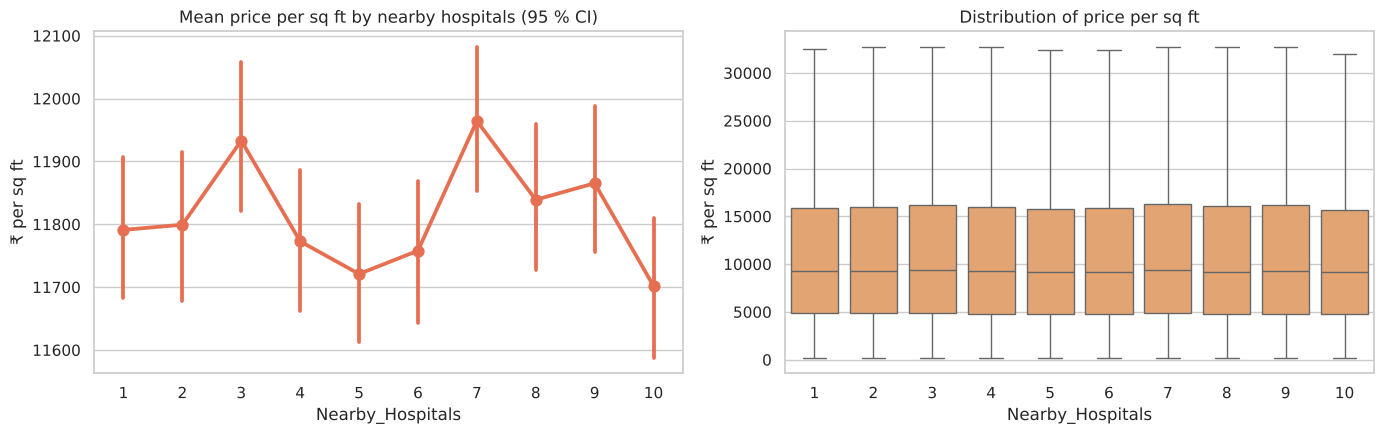

Correlation (hospitals, price/sqft): -0.0004


In [28]:
# Chart - 14 visualization code
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.pointplot(data=df, x="Nearby_Hospitals", y="Price_per_SqFt_Rs", color=BAD, errorbar=("ci", 95), ax=axes[0])
axes[0].set(title="Mean price per sq ft by nearby hospitals (95 % CI)", ylabel="₹ per sq ft")
sns.boxplot(data=df, x="Nearby_Hospitals", y="Price_per_SqFt_Rs", color="#f4a261", showfliers=False, ax=axes[1])
axes[1].set(title="Distribution of price per sq ft", ylabel="₹ per sq ft")
plt.tight_layout(); plt.show()
print("Correlation (hospitals, price/sqft):", round(df["Nearby_Hospitals"].corr(df["Price_per_SqFt_Rs"]), 4))

##### 1. Why did you pick the specific chart?

Point plot for the mean trend plus box plots for the full distribution give a complete picture of a discrete-numeric vs continuous relationship.

##### 2. What is/are the insight(s) found from the chart?

* As with schools, **price per sq ft does not change with the number of nearby hospitals** (r ≈ 0; means ≈ ₹11,700-11,960).
* The distributions are almost identical at every level.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** healthcare access is "free" in price terms; properties near more hospitals are undervalued relative to their convenience, which matters to senior citizens and families, and they score higher on infrastructure.
**Negative:** none directly, but the lack of a price premium means healthcare access alone will not lift resale value; it should be combined with transport and city tier when picking investments.

#### Chart - 15 : Price by furnished status (Brief Q14)

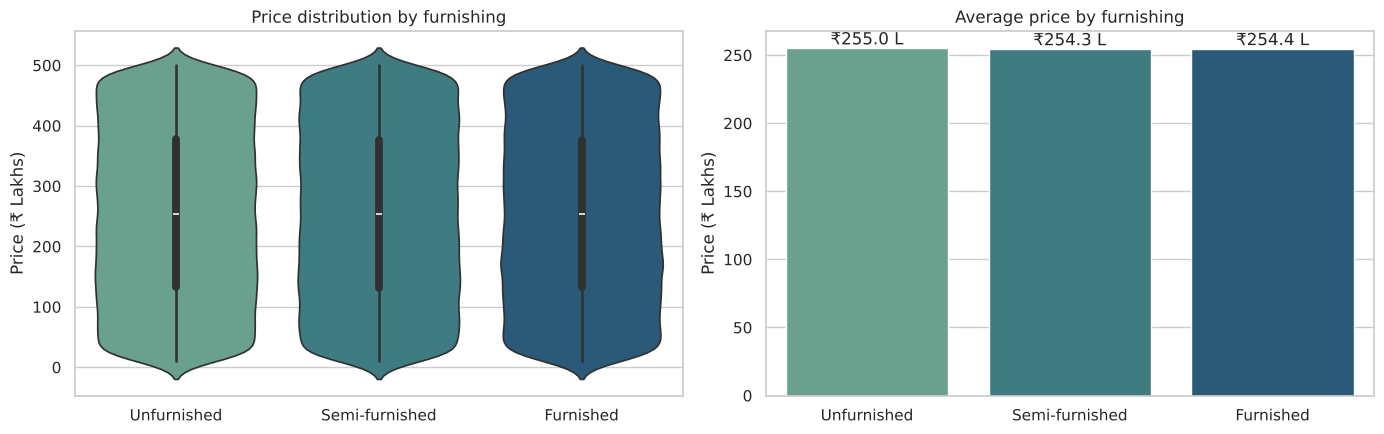

In [29]:
# Chart - 15 visualization code
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
order = ["Unfurnished", "Semi-furnished", "Furnished"]
sns.violinplot(data=df, x="Furnished_Status", y="Price_in_Lakhs", order=order, palette="crest", ax=axes[0])
axes[0].set(title="Price distribution by furnishing", xlabel="", ylabel="Price (₹ Lakhs)")
m = df.groupby("Furnished_Status")["Price_in_Lakhs"].mean().reindex(order)
sns.barplot(x=m.index, y=m.values, palette="crest", ax=axes[1])
for i, v in enumerate(m.values):
    axes[1].text(i, v, f"₹{v:.1f} L", ha="center", va="bottom")
axes[1].set(title="Average price by furnishing", xlabel="", ylabel="Price (₹ Lakhs)")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

Violin plots show both the distribution shape and the median for each category; the bar chart provides the exact averages.

##### 2. What is/are the insight(s) found from the chart?

* Furnished (≈ ₹254.4 L), semi-furnished (≈ ₹254.3 L) and unfurnished (≈ ₹255.0 L) homes cost **the same on average**.
* Distribution shapes are also identical.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** furnished homes come with fittings at no extra cost, which saves the buyer ₹ lakhs in set-up costs and makes the property rent-ready immediately — good for rental investors.
**Negative:** sellers who furnish their property do not recover that cost in the sale price, so furnishing before selling is not a value-adding strategy.

#### Chart - 16 : Price per sq ft by facing direction (Brief Q15)

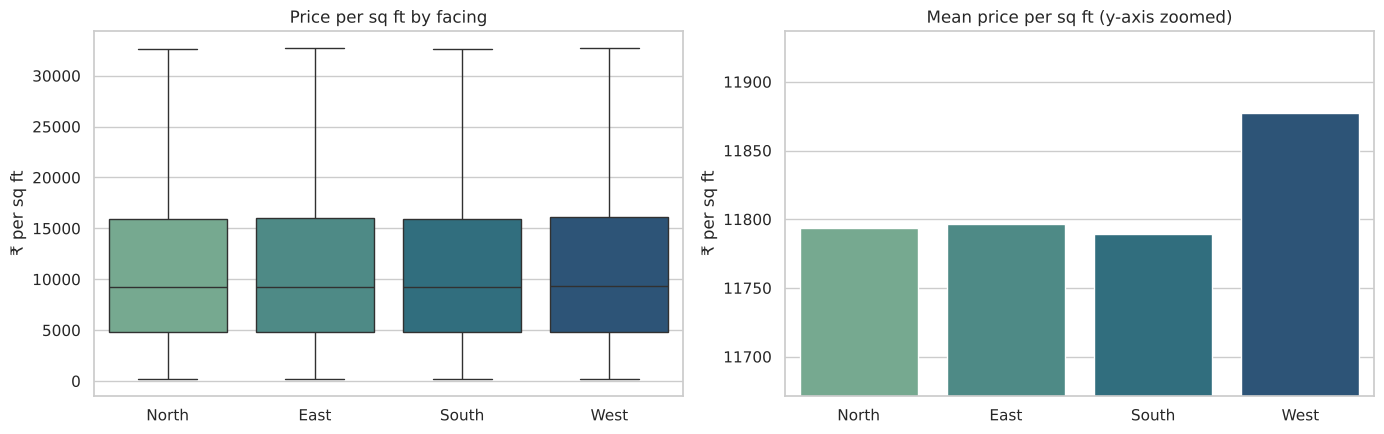

In [30]:
# Chart - 16 visualization code
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=df, x="Facing", y="Price_per_SqFt_Rs", order=["North", "East", "South", "West"],
            palette="crest", showfliers=False, ax=axes[0])
axes[0].set(title="Price per sq ft by facing", xlabel="", ylabel="₹ per sq ft")
f = df.groupby("Facing")["Price_per_SqFt_Rs"].mean().reindex(["North", "East", "South", "West"])
sns.barplot(x=f.index, y=f.values, palette="crest", ax=axes[1])
axes[1].set_ylim(f.min() * 0.99, f.max() * 1.005)
axes[1].set(title="Mean price per sq ft (y-axis zoomed)", xlabel="", ylabel="₹ per sq ft")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

Facing is a 4-level categorical variable; box plots compare distributions and a zoomed bar chart shows the small differences in means.

##### 2. What is/are the insight(s) found from the chart?

* West-facing homes average ≈ ₹11,880/sq ft versus ≈ ₹11,790-11,800 for North, East and South — a difference of **under 1 %**.
* Facing has practically no effect on price in this data.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** buyers who prefer North- or East-facing homes (often favoured for Vastu and natural light) can get them without paying any premium — an easy win when shortlisting.
**Negative:** sellers cannot expect a higher price for a "preferred" facing; marketing facing as a premium feature will not hold up against the data.

#### Chart - 17 : Does parking space affect property price? (Brief Q18)

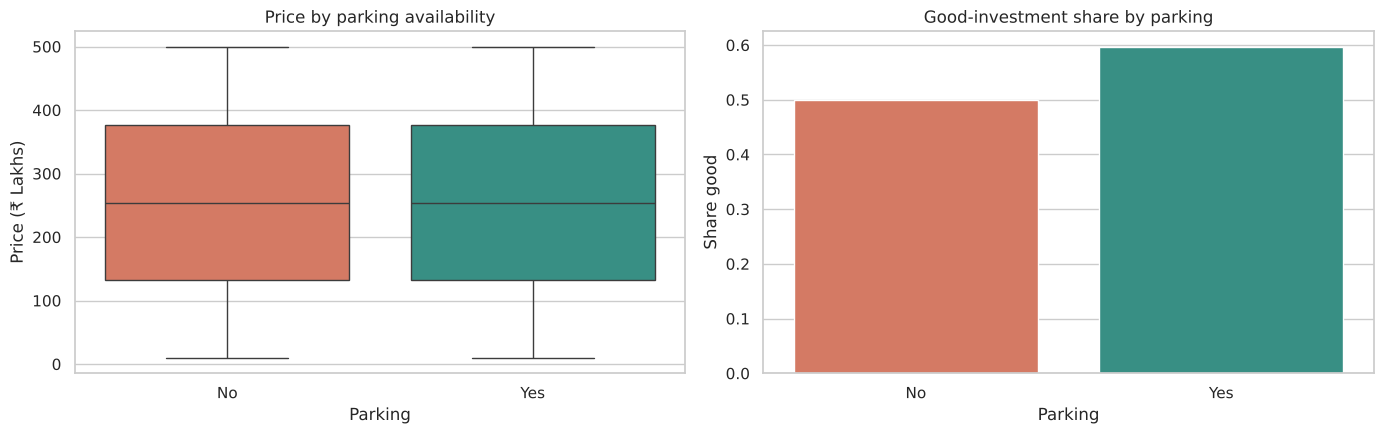

Parking_Space
No     254.4
Yes    254.7
Name: Price_in_Lakhs, dtype: float64


In [31]:
# Chart - 17 visualization code
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=df, x="Parking_Space", y="Price_in_Lakhs", palette=[BAD, GOOD], ax=axes[0])
axes[0].set(title="Price by parking availability", xlabel="Parking", ylabel="Price (₹ Lakhs)")
sns.barplot(data=df, x="Parking_Space", y="Good_Investment", palette=[BAD, GOOD], errorbar=None, ax=axes[1])
axes[1].set(title="Good-investment share by parking", xlabel="Parking", ylabel="Share good")
plt.tight_layout(); plt.show()
print(df.groupby("Parking_Space")["Price_in_Lakhs"].mean().round(1))

##### 1. Why did you pick the specific chart?

A box plot compares the full price distribution of the two groups; the second panel shows how parking relates to the investment label.

##### 2. What is/are the insight(s) found from the chart?

* Average price is **₹254.7 L with parking vs ₹254.4 L without** — parking adds no price premium.
* Listings with parking have a higher good-investment share because parking is one of the score's quality factors.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** parking — which can cost ₹3-10 L to buy separately in metro cities — comes bundled at no extra price, so investors should prefer listings with parking.
**Negative:** properties without parking are increasingly hard to rent or resell in congested cities, which can lengthen vacancy and reduce realised returns.

#### Chart - 18 : How do amenities affect price per sq ft? (Brief Q19)

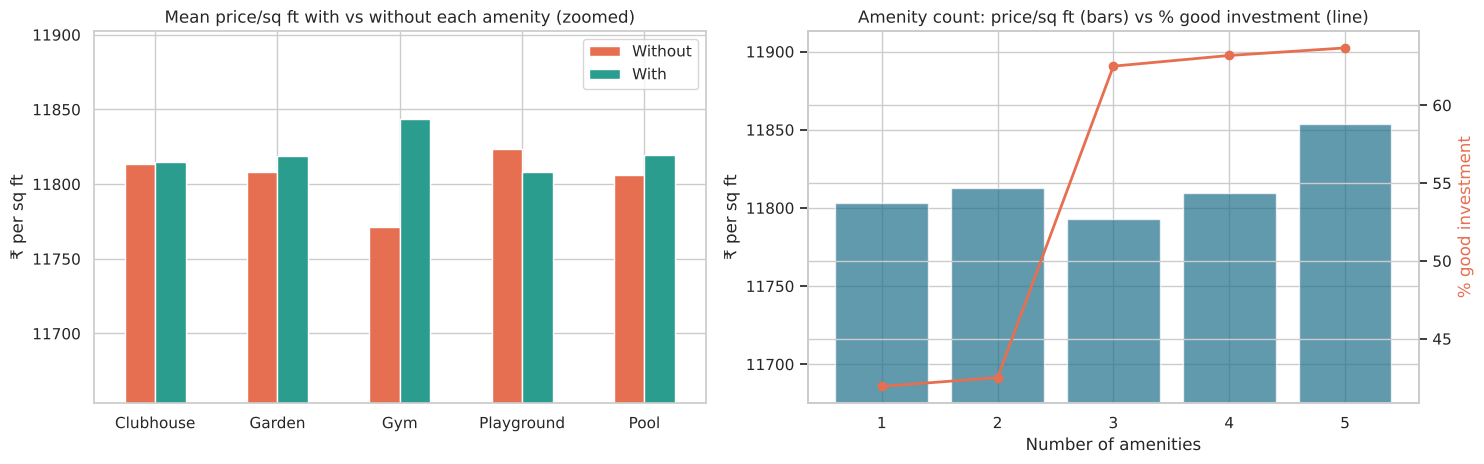

In [32]:
# Chart - 18 visualization code
amen_long = df[[f"Has_{a}" for a in cfg.AMENITY_LIST] + ["Price_per_SqFt_Rs"]].melt(
    id_vars="Price_per_SqFt_Rs", var_name="Amenity", value_name="Has")
amen_ppsf = amen_long.groupby(["Amenity", "Has"])["Price_per_SqFt_Rs"].mean().unstack()
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
amen_ppsf.rename(index=lambda s: s.replace("Has_", "")).plot(kind="bar", color=[BAD, GOOD], ax=axes[0], rot=0)
axes[0].set_ylim(amen_ppsf.values.min() * 0.99, amen_ppsf.values.max() * 1.005)
axes[0].set(title="Mean price/sq ft with vs without each amenity (zoomed)", xlabel="", ylabel="₹ per sq ft")
axes[0].legend(["Without", "With"])
cnt = df.groupby("Amenities_Count").agg(PPSF=("Price_per_SqFt_Rs", "mean"), Good=("Good_Investment", "mean"))
ax2 = axes[1]; ax3 = ax2.twinx()
ax2.bar(cnt.index, cnt["PPSF"], color=PRIMARY, alpha=0.7); ax2.set_ylim(cnt["PPSF"].min() * 0.99, cnt["PPSF"].max() * 1.005)
ax3.plot(cnt.index, cnt["Good"] * 100, color=BAD, marker="o", lw=2)
ax2.set(title="Amenity count: price/sq ft (bars) vs % good investment (line)", xlabel="Number of amenities", ylabel="₹ per sq ft")
ax3.set_ylabel("% good investment", color=BAD)
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

Grouped bars compare each amenity's effect side by side; the dual-axis chart shows how amenity count relates both to price and to the investment label.

##### 2. What is/are the insight(s) found from the chart?

* **No individual amenity raises price per sq ft** — with/without differences are below 1 %.
* Price per sq ft is flat across 1-5 amenities (≈ ₹11,800), but the **good-investment share jumps from ≈ 42 % (1-2 amenities) to ≈ 63 % (3+ amenities)**.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** amenity-rich properties cost no more but are more liveable and easier to rent, so they offer better value — buyers should shortlist listings with 3+ amenities.
**Negative:** developers who add amenities do not recover the cost through higher prices, and properties with 1-2 amenities face weaker demand, lowering their investment appeal.

#### Chart - 19 : Public transport accessibility vs price per sq ft and investment potential (Brief Q20)

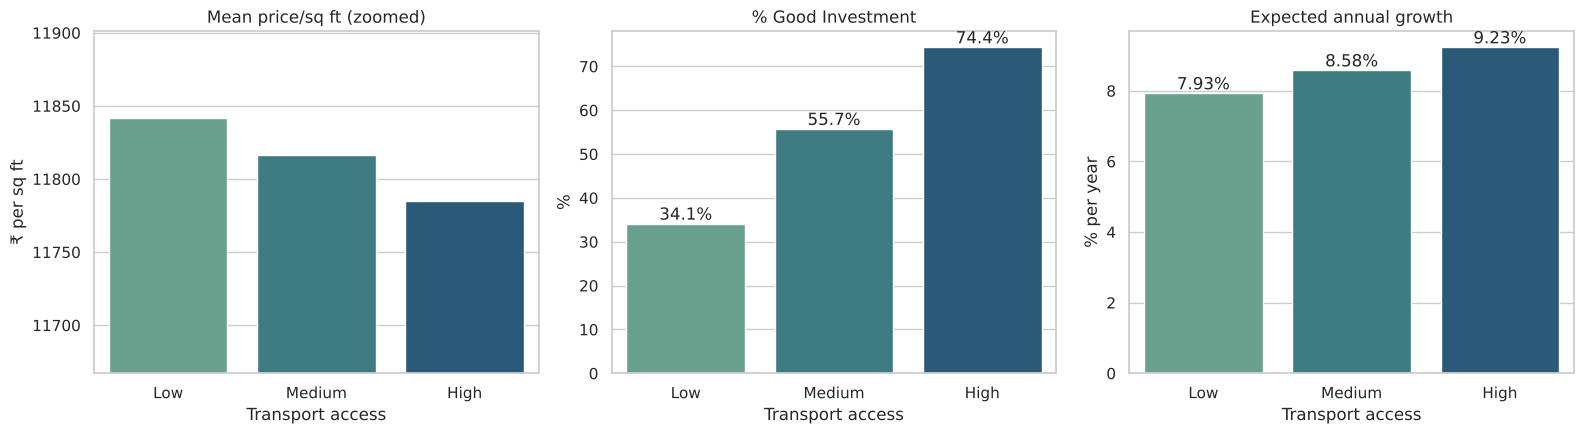

In [33]:
# Chart - 19 visualization code
order = ["Low", "Medium", "High"]
t = df.groupby("Public_Transport_Accessibility").agg(
    PPSF=("Price_per_SqFt_Rs", "mean"), Good=("Good_Investment", "mean"),
    Growth=("Expected_Growth_Rate", "mean")).reindex(order)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.barplot(x=t.index, y=t["PPSF"], palette="crest", ax=axes[0]); axes[0].set_ylim(t["PPSF"].min() * 0.99, t["PPSF"].max() * 1.005)
axes[0].set(title="Mean price/sq ft (zoomed)", xlabel="Transport access", ylabel="₹ per sq ft")
sns.barplot(x=t.index, y=t["Good"] * 100, palette="crest", ax=axes[1])
axes[1].set(title="% Good Investment", xlabel="Transport access", ylabel="%")
sns.barplot(x=t.index, y=t["Growth"] * 100, palette="crest", ax=axes[2])
axes[2].set(title="Expected annual growth", xlabel="Transport access", ylabel="% per year")
for ax, col, fmt in [(axes[1], "Good", "{:.1f}%"), (axes[2], "Growth", "{:.2f}%")]:
    for i, v in enumerate(t[col] * 100): ax.text(i, v, fmt.format(v), ha="center", va="bottom")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

Three aligned bar charts show the same grouping (transport access) against price, investment label and expected growth, making the contrast obvious.

##### 2. What is/are the insight(s) found from the chart?

* Price per sq ft is **the same** for Low, Medium and High transport access (≈ ₹11,790-11,840).
* But investment potential differs sharply: **74 % of high-access listings are good investments vs 56 % (medium) and 34 % (low)**, and expected growth is ≈ 9.2 % vs 7.9 % per year.
* Transport access is the **single most important feature** for the classifier.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** well-connected properties cost no more yet appreciate faster — the clearest buy signal in the data. Platforms should surface transport access prominently in listings.
**Negative:** low-access properties have the weakest growth (≈ 7.9 %/yr) and only a one-in-three chance of being a good investment; buyers attracted by space or amenities in poorly connected areas risk lower long-term returns.

#### Chart - 20 : Correlation between area and investment return

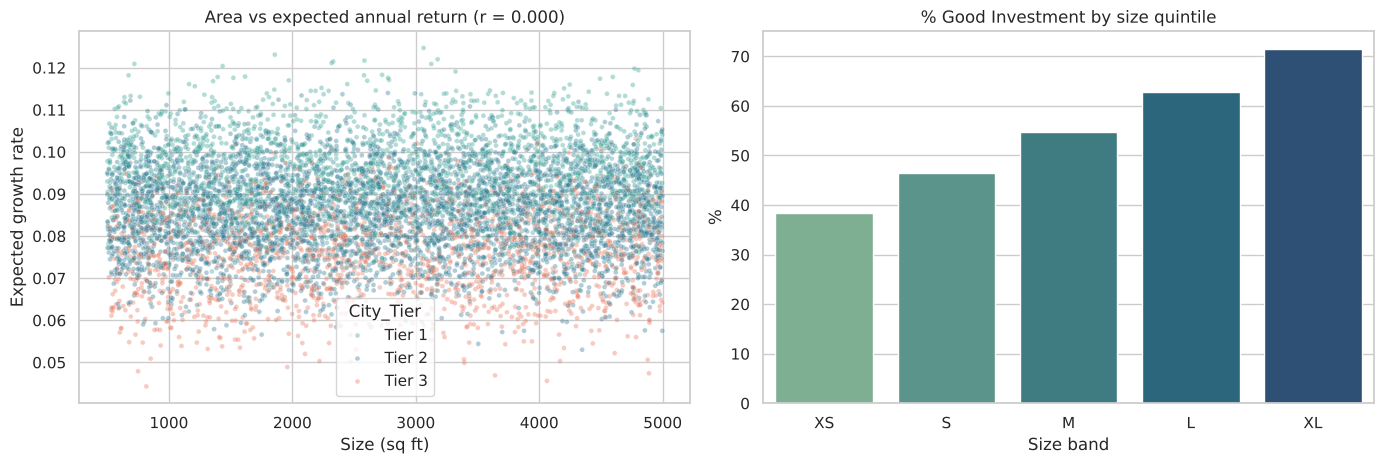

In [34]:
# Chart - 20 visualization code
sample = df.sample(8000, random_state=7)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.scatterplot(data=sample, x="Size_in_SqFt", y="Expected_Growth_Rate", hue="City_Tier",
                hue_order=["Tier 1", "Tier 2", "Tier 3"], palette=[GOOD, PRIMARY, BAD], alpha=0.35, s=12, ax=axes[0])
axes[0].set(title=f"Area vs expected annual return (r = {df['Size_in_SqFt'].corr(df['Expected_Growth_Rate']):.3f})",
            xlabel="Size (sq ft)", ylabel="Expected growth rate")
sns.boxplot(data=df.assign(Size_Band=pd.qcut(df["Size_in_SqFt"], 5, labels=["XS", "S", "M", "L", "XL"])),
            x="Size_Band", y="Good_Investment", palette="crest", showfliers=False, ax=axes[1])
size_good = df.groupby(pd.qcut(df["Size_in_SqFt"], 5, labels=["XS", "S", "M", "L", "XL"]), observed=True)["Good_Investment"].mean()
axes[1].cla(); sns.barplot(x=size_good.index, y=size_good.values * 100, palette="crest", ax=axes[1])
axes[1].set(title="% Good Investment by size quintile", xlabel="Size band", ylabel="%")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

The project brief asks for the 'correlation between area and investment return'; a scatter coloured by city tier shows whether area or location drives return, and size quintiles show the effect on the label.

##### 2. What is/are the insight(s) found from the chart?

* **Area has no correlation with expected return (r ≈ 0)**; returns separate into bands by **city tier**, not by size.
* Larger quintiles have a higher good-investment share, because large homes have a lower price per sq ft relative to the city median.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** investors can pick the size that suits their budget without sacrificing growth; **location tier** is what drives appreciation, so a smaller unit in a Tier-1 city beats a large one in a Tier-3 city on return.
**Negative:** buying a bigger home for "investment" in a weak-tier city does not improve appreciation, and capital tied up in extra area earns no extra growth.

### M - Multivariate Analysis

#### Chart - 21 : Correlation Heatmap (Brief Q11)

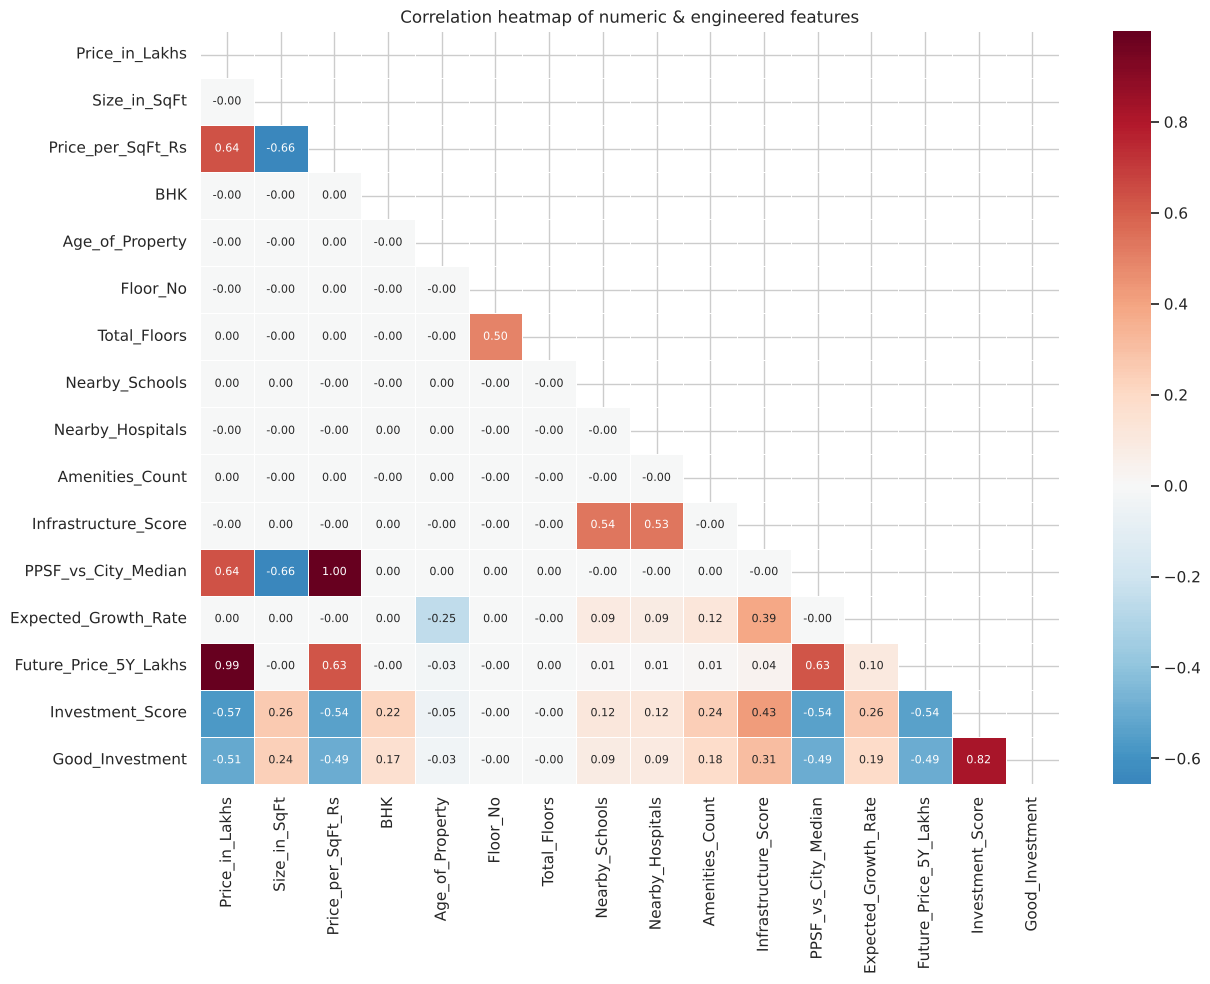

In [35]:
# Chart - 21 visualization code
num_cols = ["Price_in_Lakhs", "Size_in_SqFt", "Price_per_SqFt_Rs", "BHK", "Age_of_Property",
            "Floor_No", "Total_Floors", "Nearby_Schools", "Nearby_Hospitals", "Amenities_Count",
            "Infrastructure_Score", "PPSF_vs_City_Median", "Expected_Growth_Rate",
            "Future_Price_5Y_Lakhs", "Investment_Score", "Good_Investment"]
corr = df[num_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, linewidths=0.5,
            annot_kws={"size": 8}, ax=ax)
ax.set_title("Correlation heatmap of numeric & engineered features")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A correlation heatmap summarises every pairwise linear relationship among numeric variables in one view; masking the upper triangle removes duplicates.

##### 2. What is/are the insight(s) found from the chart?

* **Original features are almost mutually uncorrelated** (|r| < 0.01) — price is not explained by size, BHK, age, schools or hospitals.
* Strong relationships appear only where expected: `Price` ↔ `Future_Price_5Y` (0.99), `Size` ↔ `Price_per_SqFt` (-0.66), schools/hospitals ↔ `Infrastructure_Score` (0.54).
* `Investment_Score` is negatively correlated with price (-0.57) and price per sq ft (-0.54): **cheaper-than-market listings score higher**.
* No problematic multicollinearity among raw inputs; derived features are expected to correlate with their components.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** low multicollinearity means each feature adds independent information to the models. The negative score–price link confirms the advisor rewards **value buying**, which is how investors make returns.
**Negative:** the lack of correlation between price and quality features shows the market is not pricing quality efficiently; for investors this is an opportunity, but for sellers of high-quality homes it means under-realised value.

#### Chart - 22 : Pair Plot

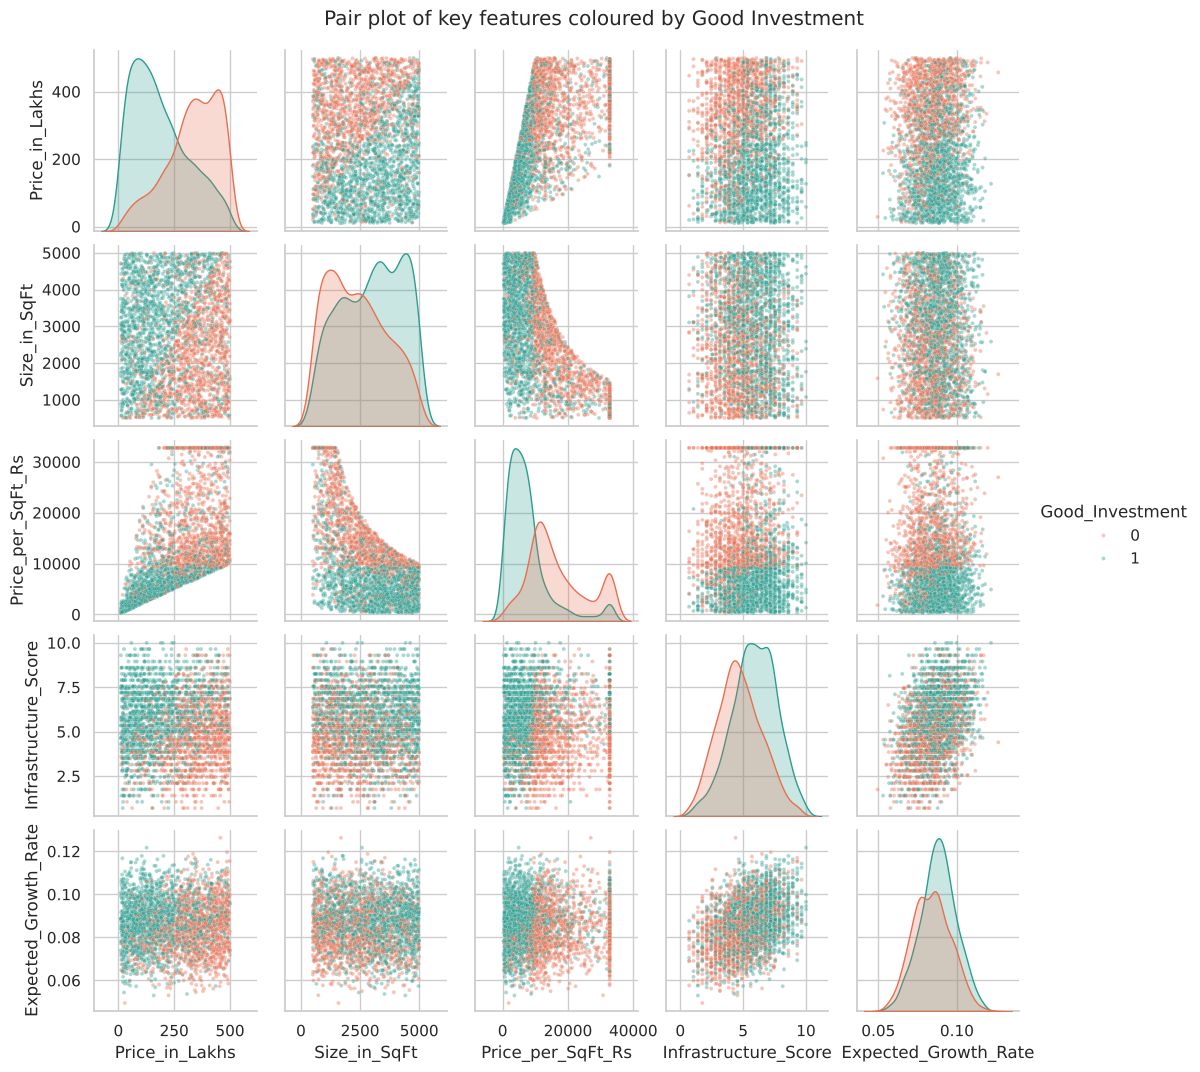

In [36]:
# Chart - 22 visualization code
pair_cols = ["Price_in_Lakhs", "Size_in_SqFt", "Price_per_SqFt_Rs", "Infrastructure_Score",
             "Expected_Growth_Rate", "Good_Investment"]
pp = sns.pairplot(df[pair_cols].sample(3000, random_state=1), hue="Good_Investment",
                  palette={0: BAD, 1: GOOD}, plot_kws={"s": 8, "alpha": 0.4}, diag_kind="kde",
                  height=2.1)
pp.figure.suptitle("Pair plot of key features coloured by Good Investment", y=1.02)
plt.show()

##### 1. Why did you pick the specific chart?

A pair plot shows every pairwise scatter plus each variable's distribution, coloured by the target, so we can see which features separate the two classes.

##### 2. What is/are the insight(s) found from the chart?

* **Good investments (green) concentrate at lower price and lower price per sq ft**, and at higher infrastructure scores and growth rates.
* Price vs size forms a uniform square cloud (no relationship), while size vs price/sq ft shows the expected inverse curve.
* No single feature separates the classes perfectly — the label depends on a combination of factors, which justifies a multi-feature ML model.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the clear shift of good investments toward lower relative price and better infrastructure validates the scoring logic and gives the platform simple talking points for buyers.
**Negative:** expensive, poorly located listings cluster in the "not good" class; sellers of such properties will see lower interest unless prices are adjusted.

#### Chart - 23 : Good-investment rate by city tier and availability status

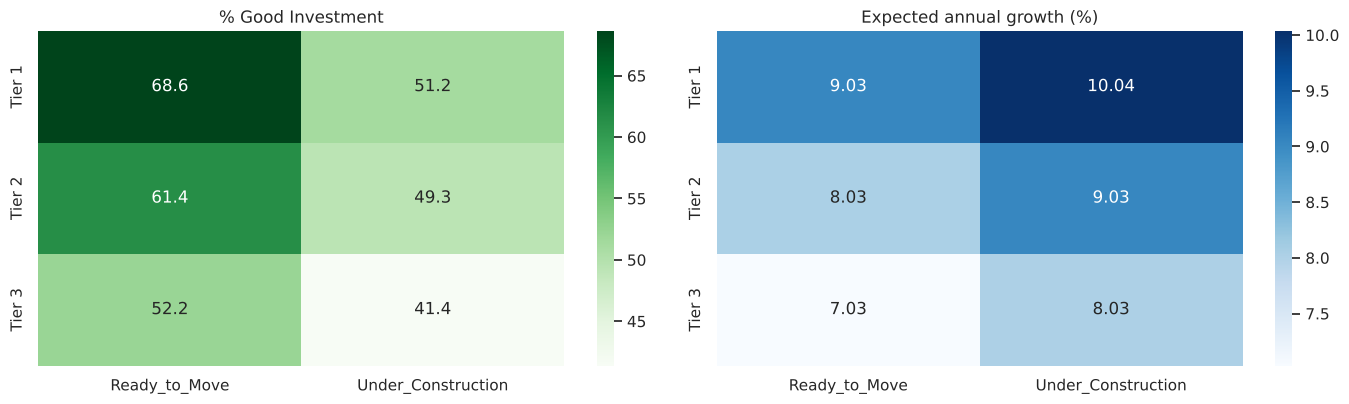

In [37]:
# Chart - 23 visualization code
pv = pd.pivot_table(df, index="City_Tier", columns="Availability_Status", values="Good_Investment", aggfunc="mean") * 100
gr = pd.pivot_table(df, index="City_Tier", columns="Availability_Status", values="Expected_Growth_Rate", aggfunc="mean") * 100
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
sns.heatmap(pv, annot=True, fmt=".1f", cmap="Greens", ax=axes[0]); axes[0].set_title("% Good Investment")
sns.heatmap(gr, annot=True, fmt=".2f", cmap="Blues", ax=axes[1]); axes[1].set_title("Expected annual growth (%)")
for ax in axes: ax.set(xlabel="", ylabel="")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

Two heatmaps over the same tier × status grid compare the investment label and the growth rate across three variables at once.

##### 2. What is/are the insight(s) found from the chart?

* **Tier-1 ready-to-move** property has the highest good-investment share (68.6 %); **Tier-3 under-construction** the lowest (41.4 %).
* Under-construction property shows **higher expected growth** (completion premium, ≈ 9.1 % vs 8.1 %) but a **lower good-investment share** because of delivery risk — a classic risk/return trade-off.
* Tier-1 cities grow ≈ 2 percentage points faster per year than Tier-3 cities.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** risk-averse buyers should prefer ready-to-move homes in Tier-1/2 cities; return-seeking investors can accept construction risk for ~1 % extra annual growth. The app can tailor recommendations to each profile.
**Negative:** Tier-3 under-construction projects combine weak growth and delivery risk — only 41 % qualify as good investments, so platforms should flag them clearly.

#### Chart - 24 : Infrastructure score vs future resale value across city tiers

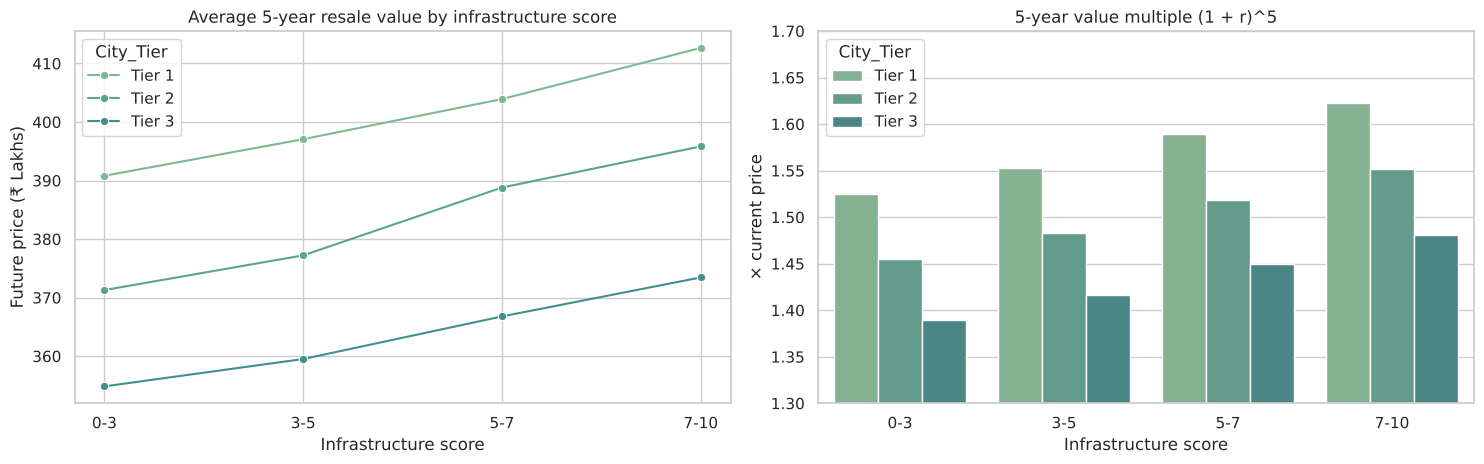

In [38]:
# Chart - 24 visualization code
bands = pd.cut(df["Infrastructure_Score"], [0, 3, 5, 7, 10], labels=["0-3", "3-5", "5-7", "7-10"])
infra = (df.assign(Infra_Band=bands)
           .groupby(["Infra_Band", "City_Tier"], observed=True)
           .agg(Future=("Future_Price_5Y_Lakhs", "mean"), Mult=("Expected_Growth_Rate", "mean"))
           .reset_index())
infra["Value_Multiple"] = (1 + infra["Mult"]) ** 5
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
sns.lineplot(data=infra, x="Infra_Band", y="Future", hue="City_Tier", marker="o", ax=axes[0],
             hue_order=["Tier 1", "Tier 2", "Tier 3"])
axes[0].set(title="Average 5-year resale value by infrastructure score", xlabel="Infrastructure score",
            ylabel="Future price (₹ Lakhs)")
sns.barplot(data=infra, x="Infra_Band", y="Value_Multiple", hue="City_Tier", ax=axes[1],
            hue_order=["Tier 1", "Tier 2", "Tier 3"])
axes[1].set_ylim(1.3, 1.7)
axes[1].set(title="5-year value multiple (1 + r)^5", xlabel="Infrastructure score", ylabel="× current price")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

The brief asks for the 'relationship between infrastructure score and resale value'; line and grouped bar charts show this relationship separately for each city tier (three variables).

##### 2. What is/are the insight(s) found from the chart?

* **Resale value rises steadily with the infrastructure score in every tier**: average 5-year value grows from ≈ ₹373 L (score 0-3) to ≈ ₹396 L (score 7-10).
* The 5-year value multiple is highest for **Tier-1 cities with infrastructure 7-10 (≈ 1.62×)** and lowest for Tier-3 with weak infrastructure (≈ 1.39×).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** infrastructure and location tier compound each other — investors get the best resale outcome by combining both, and developers can justify investment in nearby social infrastructure.
**Negative:** low-infrastructure Tier-3 properties grow only ~1.39× in five years, close to inflation-adjusted break-even once costs are included, so they are poor investments.

#### Chart - 25 : Good-investment share by BHK and number of amenities

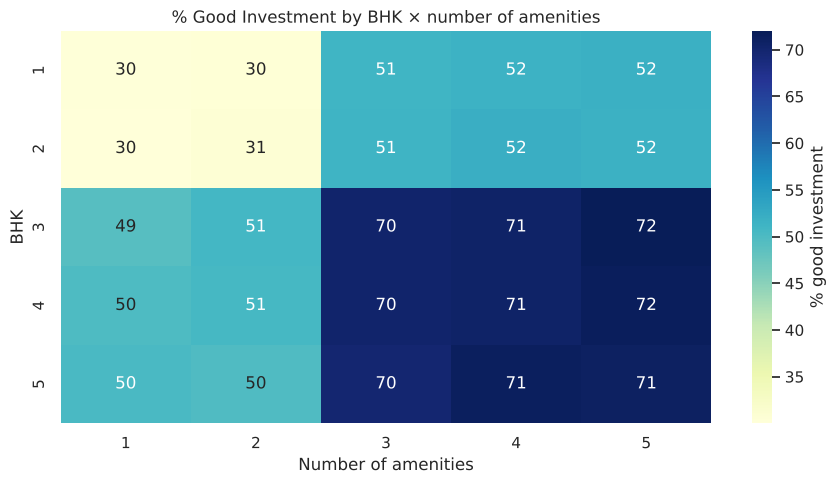

In [39]:
# Chart - 25 visualization code
pv = pd.pivot_table(df, index="BHK", columns="Amenities_Count", values="Good_Investment", aggfunc="mean") * 100
fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(pv, annot=True, fmt=".0f", cmap="YlGnBu", cbar_kws={"label": "% good investment"}, ax=ax)
ax.set(title="% Good Investment by BHK × number of amenities", xlabel="Number of amenities", ylabel="BHK")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A heatmap of a target rate across two categorical dimensions shows interaction effects that single-variable charts can't reveal.

##### 2. What is/are the insight(s) found from the chart?

* The best combination is **3-5 BHK with 3+ amenities (≈ 70-72 % good investments)**; the worst is **1-2 BHK with 1-2 amenities (≈ 30 %)**.
* Both factors add up: moving from 2 to 3 BHK adds ≈ 20 points, and moving from 2 to 3 amenities adds another ≈ 20 points.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** a simple, actionable screening rule for investors and listing teams: target family-size homes with at least three amenities.
**Negative:** small units with few amenities make up a large share of supply but rarely qualify as good investments; sellers of such units may face longer time-on-market.

## **5. Solution to Business Objective**

#### What do you suggest the client to achieve Business Objective ?
Explain Briefly.

1. **Judge value relative to the market, not by sticker price.** Prices are nearly flat across cities, states, property types and features, so the most reliable value signal is a listing's **price per sq ft compared with its city median**. The advisor surfaces this for every property.
2. **Prioritise connectivity and location tier.** High public-transport access lifts the good-investment share from 34 % to 74 % and adds ~1.3 points of annual growth; Tier-1 cities add ~2 points over Tier-3 at the same entry price.
3. **Target family-size homes with amenities.** 3+ BHK homes with 3+ amenities qualify as good investments ~70 % of the time vs ~30 % for small, basic units.
4. **Match construction stage to risk appetite.** Ready-to-move homes are safer (higher good-investment share); under-construction homes give ~1 % extra annual growth for buyers who accept delivery risk.
5. **Use free "extras".** Parking, furnishing, security, preferred facing and proximity to schools and hospitals carry **no price premium** in this data — buyers should insist on them.
6. **Deploy the Streamlit advisor** so investors get an instant verdict with a confidence score, a 5-year forecast, a factor checklist and market dashboards, and so the platform can screen its whole inventory automatically. All models are tracked and versioned in MLflow, so they can be retrained as real transaction data becomes available.

# **Conclusion**

* The 250,000-listing dataset was cleaned (floor inconsistencies fixed, price per sq ft rebuilt and outliers capped) and enriched with **infrastructure, school-density, amenity, city-tier and market-relative features**.
* EDA across **25 charts** shows a market where listed prices are almost uniform and do **not** reflect size, location quality or amenities. The real differentiators of investment quality are **relative price, transport access, city tier, BHK, amenities and readiness**.
* Two targets were defined from transparent domain rules: a 5-year future price (`Price × (1 + r)^5`) and a multi-factor Good Investment label (54.8 % positive).
* **XGBoost** delivered the best models: **99.6 % accuracy / 0.996 F1** for classification and **R² 0.998 / RMSE ≈ ₹10 L** for the 5-year price, all logged and registered in **MLflow**.
* A Streamlit application turns these models into a practical tool for investors, buyers and real-estate platforms.
* **Limitations & next steps:** the data has no historical transactions, crime rate or RERA status, so the targets are rule-based; with real price history the same pipeline can learn actual appreciation and the rules can be replaced by observed returns.

### ***Hurrah! You have successfully completed your EDA Capstone Project !!!***